In [40]:
# =========================================================
# 0. LIBRERÍAS
# =========================================================
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy import stats
from scipy.spatial import distance
import seaborn as sns

from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

sns.set_theme(style="whitegrid", context="notebook")

In [41]:
# =========================================================
# 1. CARGA DE DATOS
# =========================================================
df = pd.read_csv("smartwatch_sleep_dataset.csv")

print("Dimensiones del dataset:", df.shape)
display(df.head())
display(df.info())

Dimensiones del dataset: (20000, 45)


,user_id,date_recorded,sleep_start_timestamp,sleep_end_timestamp,duration_minutes,sleep_latency_minutes,wake_after_sleep_onset_minutes,sleep_efficiency_pct,sleep_score,daily_label,...,height_cm,device_model,bedtime_consistency_std_min,stress_score,activity_before_bed_min,screen_time_before_bed_min,insomnia_flag,apnea_risk_score,nap_duration_minutes,created_at
0,user_00332,2024-04-03,2024-04-03 22:36:00,2024-04-04 06:01:00,445,2,15,96.2,59,fair,...,166.1,AlphaWatch X1,37.1,33,39,87,0,24,10,2025-10-21 16:41:53.708868
1,user_00677,2018-12-05,2018-12-05 23:41:00,2018-12-06 04:36:00,295,18,1,93.6,61,fair,...,172.4,AlphaWatch X1,9.6,20,1,0,0,15,9,2025-10-21 16:41:53.709912
2,user_01815,2025-03-30,2025-03-30 23:41:00,2025-03-31 06:56:00,435,6,50,87.1,58,fair,...,158.0,PulsePro 3,35.5,29,5,37,0,33,0,2025-10-21 16:41:53.711057
3,user_00488,2023-05-11,2023-05-11 22:24:00,2023-05-12 06:10:00,466,10,12,95.3,53,fair,...,152.6,WristFit Z,65.4,41,69,71,0,8,3,2025-10-21 16:41:53.712147
4,user_00498,2019-12-11,2019-12-11 22:17:00,2019-12-12 04:29:00,372,1,2,99.2,60,fair,...,155.1,WristFit Z,0.4,54,49,31,0,26,5,2025-10-21 16:41:53.713204


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 45 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   user_id                         20000 non-null  object 
 1   date_recorded                   20000 non-null  object 
 2   sleep_start_timestamp           20000 non-null  object 
 3   sleep_end_timestamp             20000 non-null  object 
 4   duration_minutes                20000 non-null  int64  
 5   sleep_latency_minutes           20000 non-null  int64  
 6   wake_after_sleep_onset_minutes  20000 non-null  int64  
 7   sleep_efficiency_pct            20000 non-null  float64
 8   sleep_score                     20000 non-null  int64  
 9   daily_label                     20000 non-null  object 
 10  sleep_stage_deep_pct            20000 non-null  float64
 11  sleep_stage_light_pct           20000 non-null  float64
 12  sleep_stage_rem_pct             

None

In [42]:
# =========================================================
# 2. SELECCIÓN DE VARIABLES DEL ANÁLISIS
# =========================================================
dependent_vars = [
    "sleep_score",
    "sleep_latency_minutes",
    "duration_minutes"
]

independent_vars_cont = [
    "caffeine_mg",
    "stress_score",
    "screen_time_before_bed_min"
]

analysis_vars = dependent_vars + independent_vars_cont

df_model = df[analysis_vars].copy()
display(df_model.head())
display(df_model.describe().T)

,sleep_score,sleep_latency_minutes,duration_minutes,caffeine_mg,stress_score,screen_time_before_bed_min
0,59,2,445,126,33,87
1,61,18,295,92,20,0
2,58,6,435,150,29,37
3,53,10,466,83,41,71
4,60,1,372,29,54,31


,count,mean,std,min,25%,50%,75%,max
sleep_score,20000.0,57.86195,5.368606,31.0,55.0,58.0,62.0,76.0
sleep_latency_minutes,20000.0,9.66030,10.171415,0.0,2.0,7.0,13.0,102.0
duration_minutes,20000.0,449.18885,71.884421,151.0,400.0,449.0,498.0,720.0
caffeine_mg,20000.0,84.00645,52.086769,0.0,42.0,80.0,119.0,300.0
stress_score,20000.0,34.81975,17.490442,0.0,22.0,34.0,47.0,100.0
screen_time_before_bed_min,20000.0,56.18910,36.958300,0.0,28.0,55.0,82.0,210.0


In [43]:
# =========================================================
# 3. LIMPIEZA BÁSICA
# =========================================================
# Revisar valores perdidos
print("Valores perdidos por variable:")
print(df_model.isna().sum())

# Eliminar filas con NA solo en las variables del modelo
df_model = df_model.dropna().copy()

print("Dimensiones luego de dropna:", df_model.shape)

# Revisar duplicados
print("Filas duplicadas:", df_model.duplicated().sum())

Valores perdidos por variable:
sleep_score                   0
sleep_latency_minutes         0
duration_minutes              0
caffeine_mg                   0
stress_score                  0
screen_time_before_bed_min    0
dtype: int64
Dimensiones luego de dropna: (20000, 6)
Filas duplicadas: 0


In [44]:
# =========================================================
# 4. CATEGORIZACIÓN DE LAS VARIABLES INDEPENDIENTES
# =========================================================
# Para poder hacer MANOVA/ANOVA de 3 vías, convertimos las
# variables continuas en factores categóricos de 3 niveles.

labels_3 = ["Bajo", "Medio", "Alto"]

df_model["caffeine_group"] = pd.qcut(
    df_model["caffeine_mg"],
    q=3,
    labels=labels_3
)

df_model["stress_group"] = pd.qcut(
    df_model["stress_score"],
    q=3,
    labels=labels_3
)

df_model["screen_group"] = pd.qcut(
    df_model["screen_time_before_bed_min"],
    q=3,
    labels=labels_3
)

# Grupo combinado para Box's M y revisiones por celda
df_model["combined_group"] = (
    df_model["caffeine_group"].astype(str) + "_" +
    df_model["stress_group"].astype(str) + "_" +
    df_model["screen_group"].astype(str)
)

display(df_model[[
    "caffeine_mg", "caffeine_group",
    "stress_score", "stress_group",
    "screen_time_before_bed_min", "screen_group"
]].head())

print(df_model["caffeine_group"].value_counts())
print(df_model["stress_group"].value_counts())
print(df_model["screen_group"].value_counts())

,caffeine_mg,caffeine_group,stress_score,stress_group,screen_time_before_bed_min,screen_group
0,126,Alto,33,Medio,87,Alto
1,92,Medio,20,Bajo,0,Bajo
2,150,Alto,29,Medio,37,Bajo
3,83,Medio,41,Medio,71,Medio
4,29,Bajo,54,Alto,31,Bajo


caffeine_group
Medio    6716
Bajo     6677
Alto     6607
Name: count, dtype: int64
stress_group
Bajo     6908
Alto     6580
Medio    6512
Name: count, dtype: int64
screen_group
Medio    6771
Bajo     6683
Alto     6546
Name: count, dtype: int64


In [45]:
# =========================================================
# 5. DICCIONARIO BÁSICO DE VARIABLES
# =========================================================
diccionario = pd.DataFrame({
    "Variable": [
        "sleep_score",
        "sleep_latency_minutes",
        "duration_minutes",
        "caffeine_mg",
        "stress_score",
        "screen_time_before_bed_min",
        "caffeine_group",
        "stress_group",
        "screen_group"
    ],
    "Tipo": [
        "Dependiente cuantitativa",
        "Dependiente cuantitativa",
        "Dependiente cuantitativa",
        "Independiente cuantitativa",
        "Independiente cuantitativa",
        "Independiente cuantitativa",
        "Factor categórico ordinal",
        "Factor categórico ordinal",
        "Factor categórico ordinal"
    ],
    "Unidad / escala": [
        "Puntaje",
        "Minutos",
        "Minutos",
        "mg",
        "Puntaje",
        "Minutos",
        "Bajo/Medio/Alto",
        "Bajo/Medio/Alto",
        "Bajo/Medio/Alto"
    ]
})

display(diccionario)

,Variable,Tipo,Unidad / escala
0,sleep_score,Dependiente cuantitativa,Puntaje
1,sleep_latency_minutes,Dependiente cuantitativa,Minutos
2,duration_minutes,Dependiente cuantitativa,Minutos
3,caffeine_mg,Independiente cuantitativa,mg
4,stress_score,Independiente cuantitativa,Puntaje
5,screen_time_before_bed_min,Independiente cuantitativa,Minutos
6,caffeine_group,Factor categórico ordinal,Bajo/Medio/Alto
7,stress_group,Factor categórico ordinal,Bajo/Medio/Alto
8,screen_group,Factor categórico ordinal,Bajo/Medio/Alto


In [46]:
# =========================================================
# 6. ESTADÍSTICA DESCRIPTIVA UNIVARIADA
# =========================================================
desc_univar = pd.DataFrame(index=analysis_vars)

desc_univar["media"] = df_model[analysis_vars].mean()
desc_univar["mediana"] = df_model[analysis_vars].median()
desc_univar["moda"] = df_model[analysis_vars].mode().iloc[0]
desc_univar["std"] = df_model[analysis_vars].std()
desc_univar["varianza"] = df_model[analysis_vars].var()
desc_univar["mínimo"] = df_model[analysis_vars].min()
desc_univar["máximo"] = df_model[analysis_vars].max()
desc_univar["rango"] = desc_univar["máximo"] - desc_univar["mínimo"]
desc_univar["Q1"] = df_model[analysis_vars].quantile(0.25)
desc_univar["Q3"] = df_model[analysis_vars].quantile(0.75)
desc_univar["IQR"] = desc_univar["Q3"] - desc_univar["Q1"]
desc_univar["asimetría"] = df_model[analysis_vars].skew()
desc_univar["curtosis"] = df_model[analysis_vars].kurt()

display(desc_univar.round(3))

,media,mediana,moda,std,varianza,mínimo,máximo,rango,Q1,Q3,IQR,asimetría,curtosis
sleep_score,57.862,58.0,58,5.369,28.822,31,76,45,55.0,62.0,7.0,-0.353,0.387
sleep_latency_minutes,9.660,7.0,0,10.171,103.458,0,102,102,2.0,13.0,11.0,2.016,5.905
duration_minutes,449.189,449.0,468,71.884,5167.370,151,720,569,400.0,498.0,98.0,0.026,-0.009
caffeine_mg,84.006,80.0,81,52.087,2713.031,0,300,300,42.0,119.0,77.0,0.493,-0.212
stress_score,34.820,34.0,0,17.490,305.916,0,100,100,22.0,47.0,25.0,0.145,-0.285
screen_time_before_bed_min,56.189,55.0,0,36.958,1365.916,0,210,210,28.0,82.0,54.0,0.343,-0.420


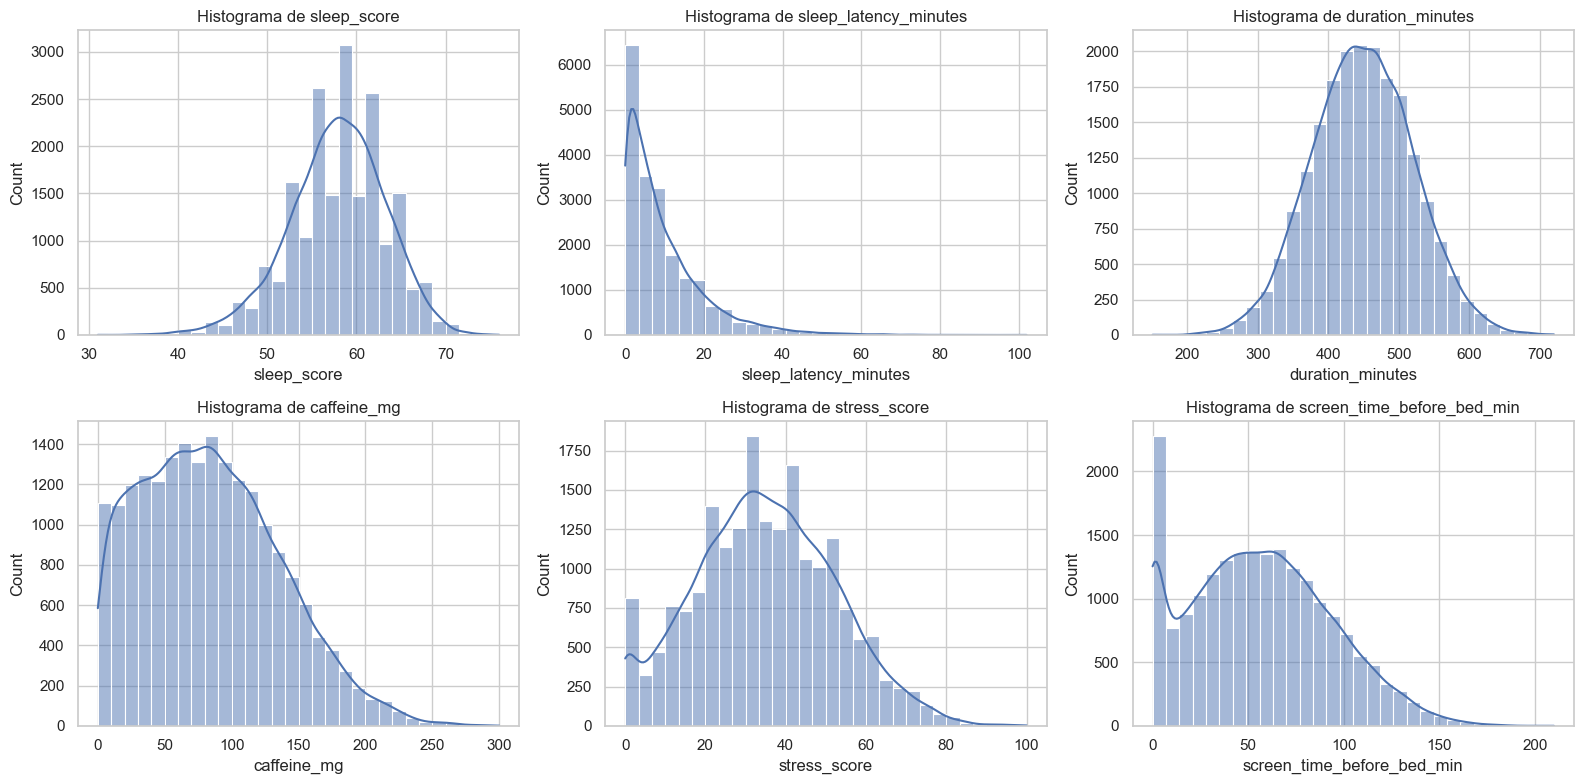

In [47]:
# =========================================================
# 7. HISTOGRAMAS + KDE
# =========================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, var in enumerate(analysis_vars):
    sns.histplot(df_model[var], kde=True, bins=30, ax=axes[i])
    axes[i].set_title(f"Histograma de {var}")

plt.tight_layout()
plt.show()

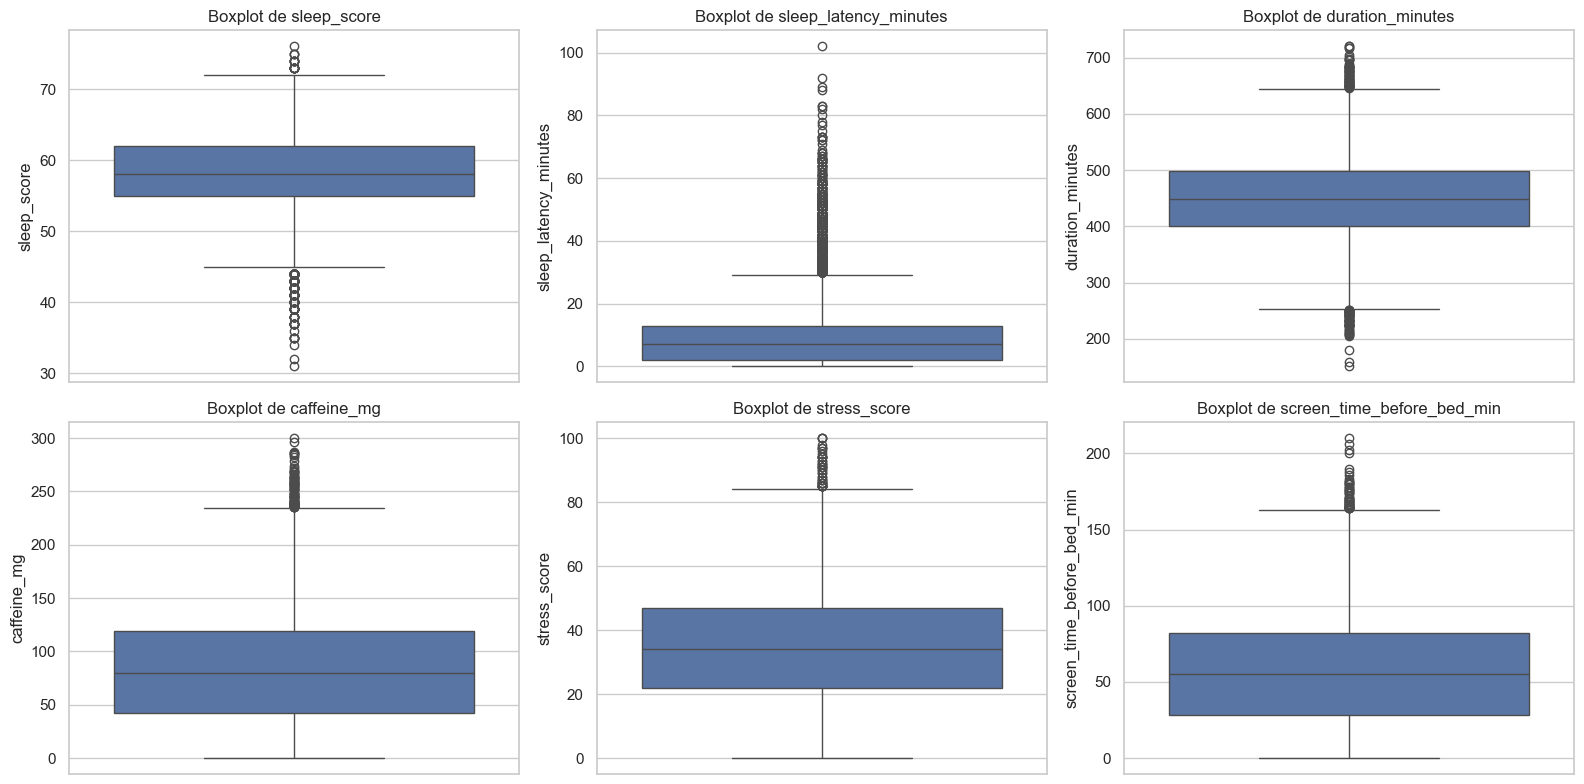

In [48]:
# =========================================================
# 8. BOXPLOTS UNIVARIADOS
# =========================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, var in enumerate(analysis_vars):
    sns.boxplot(y=df_model[var], ax=axes[i])
    axes[i].set_title(f"Boxplot de {var}")

plt.tight_layout()
plt.show()

In [49]:
# =========================================================
# 9. DESCRIPTIVA POR GRUPOS
# =========================================================
for factor in ["caffeine_group", "stress_group", "screen_group"]:
    print(f"\n================ {factor} ================\n")
    display(df_model.groupby(factor)[dependent_vars].agg(["mean", "median", "std", "var"]).round(3))


================ caffeine_group ================



C:\Users\USUARIO\AppData\Local\Temp\ipykernel_14792\380701640.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df_model.groupby(factor)[dependent_vars].agg(["mean", "median", "std", "var"]).round(3))


sleep_score                       sleep_latency_minutes         \
                      mean median    std     var                  mean median   
caffeine_group                                                                  
Bajo                57.854   58.0  5.396  29.113                 9.594    6.0   
Medio               57.839   58.0  5.371  28.848                 9.844    7.0   
Alto                57.894   58.0  5.339  28.508                 9.540    7.0   

                                duration_minutes                           
                   std      var             mean median     std       var  
caffeine_group                                                             
Bajo            10.128  102.582          450.177  450.0  71.199  5069.242  
Medio           10.486  109.954          449.010  448.0  72.038  5189.464  
Alto             9.885   97.717          448.372  448.0  72.415  5243.957


================ stress_group ================



C:\Users\USUARIO\AppData\Local\Temp\ipykernel_14792\380701640.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df_model.groupby(factor)[dependent_vars].agg(["mean", "median", "std", "var"]).round(3))


sleep_score                       sleep_latency_minutes         \
                    mean median    std     var                  mean median   
stress_group                                                                  
Bajo              60.652   61.0  4.890  23.912                 9.674    6.0   
Medio             57.891   58.0  4.647  21.599                 9.676    7.0   
Alto              54.904   55.0  4.920  24.211                 9.630    7.0   

                              duration_minutes                           
                 std      var             mean median     std       var  
stress_group                                                             
Bajo          10.327  106.652          449.590  449.0  71.850  5162.384  
Medio         10.235  104.759          449.041  450.0  71.781  5152.549  
Alto           9.942   98.846          448.914  448.0  72.032  5188.578


================ screen_group ================



C:\Users\USUARIO\AppData\Local\Temp\ipykernel_14792\380701640.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df_model.groupby(factor)[dependent_vars].agg(["mean", "median", "std", "var"]).round(3))


sleep_score                       sleep_latency_minutes         \
                    mean median    std     var                  mean median   
screen_group                                                                  
Bajo              57.857   58.0  5.358  28.711                 9.614    6.0   
Medio             57.812   58.0  5.394  29.094                 9.667    7.0   
Alto              57.919   58.0  5.353  28.657                 9.701    7.0   

                              duration_minutes                           
                 std      var             mean median     std       var  
screen_group                                                             
Bajo          10.228  104.606          448.088  448.0  71.759  5149.422  
Medio         10.116  102.337          449.405  450.0  71.735  5145.934  
Alto          10.172  103.471          450.089  448.5  72.162  5207.349

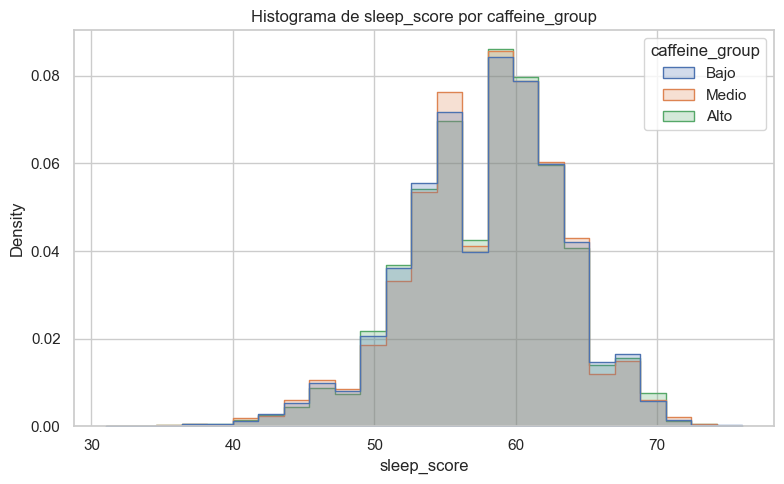

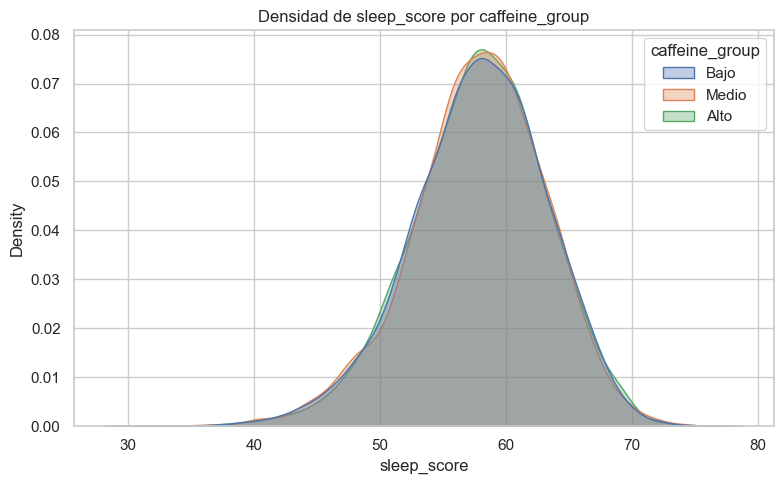

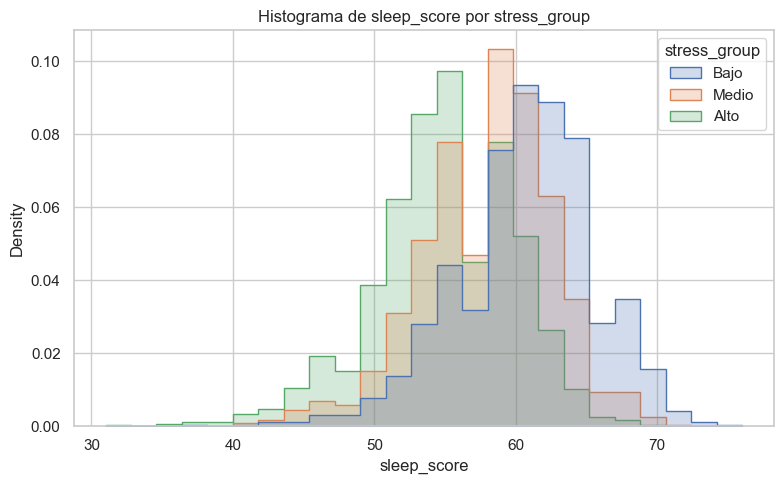

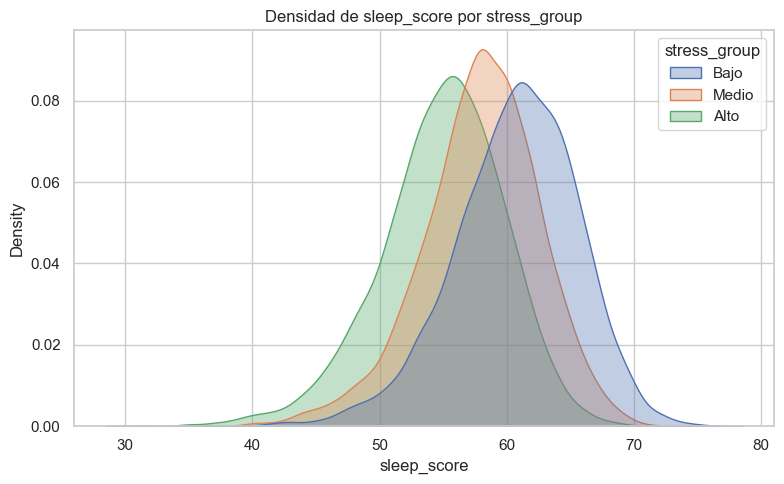

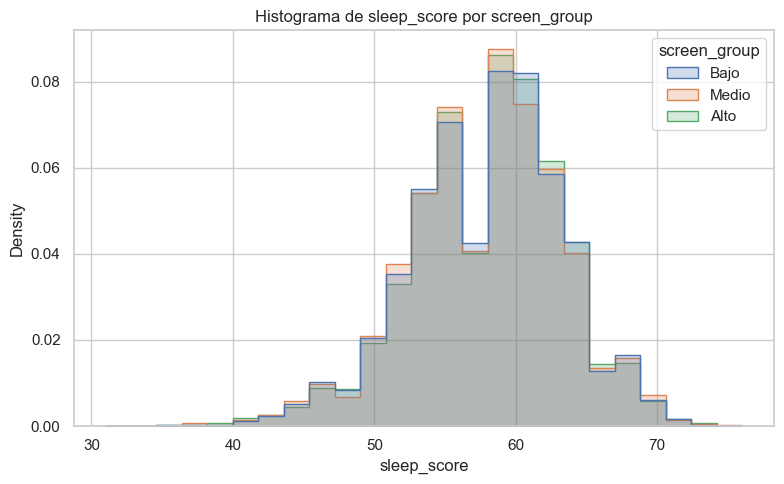

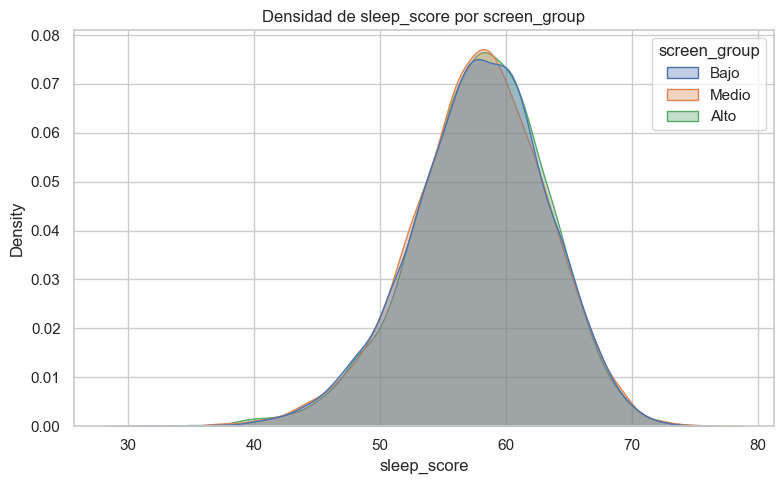

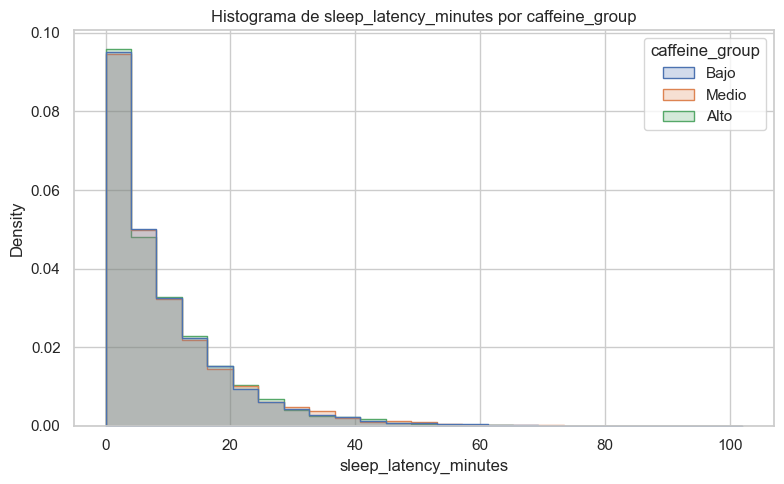

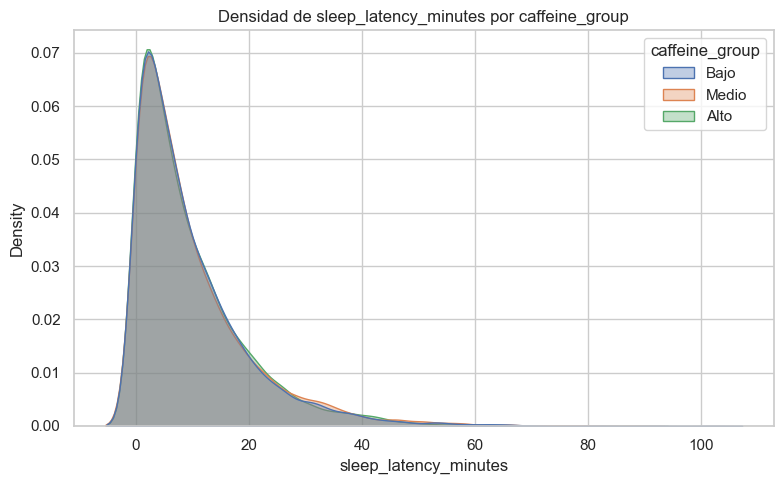

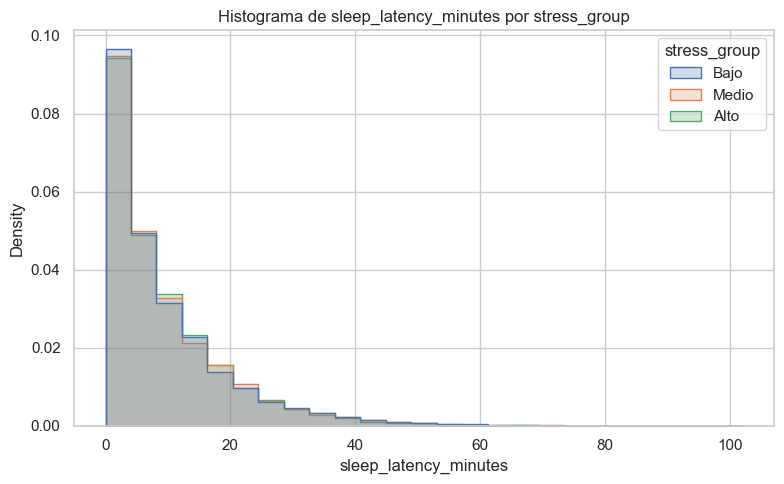

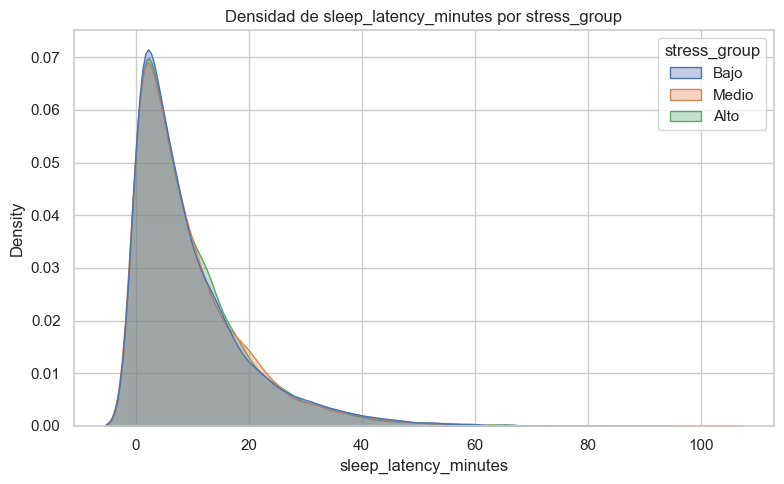

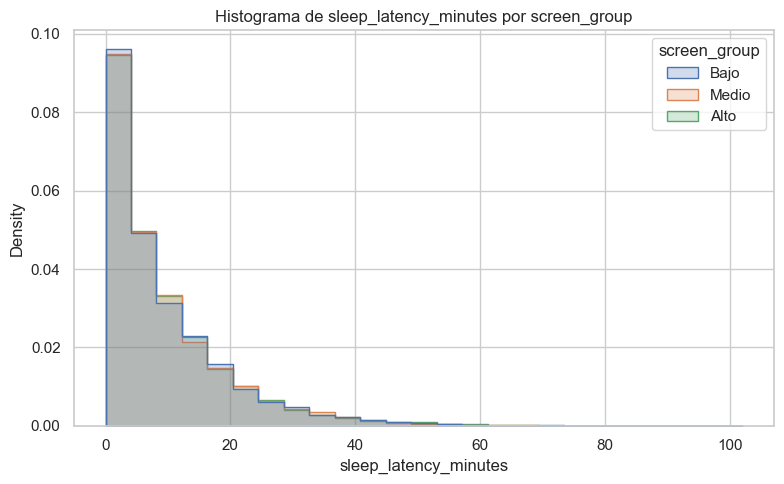

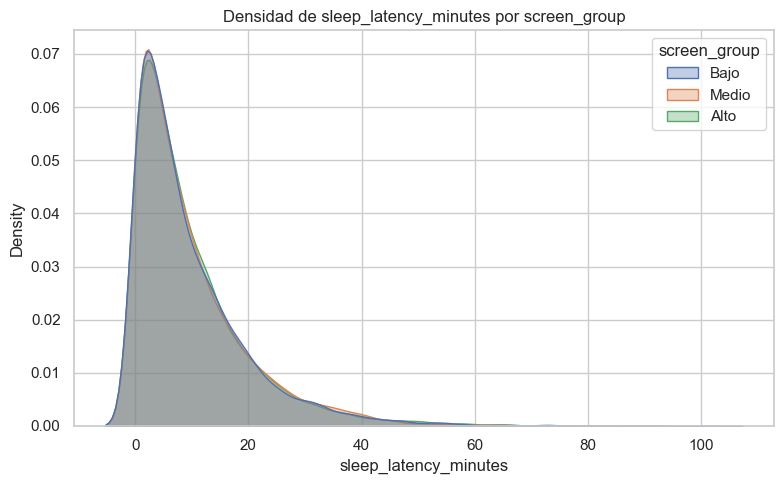

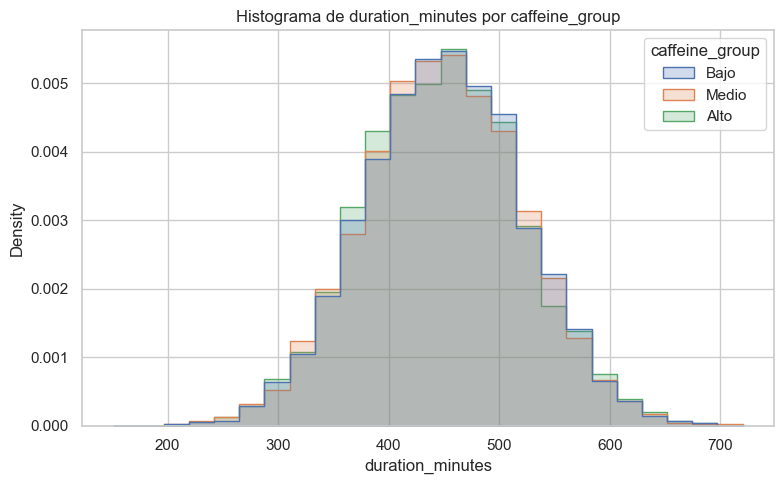

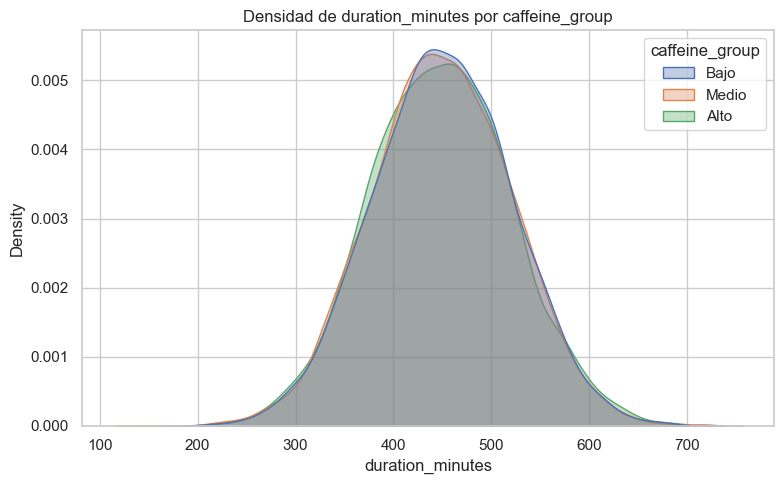

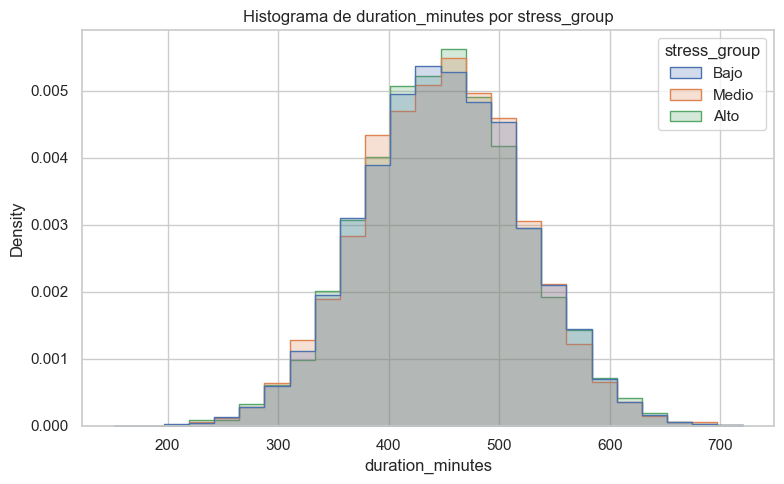

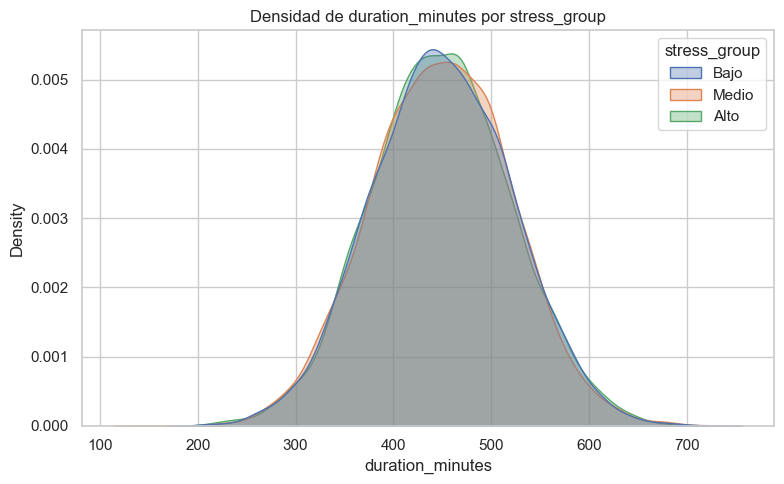

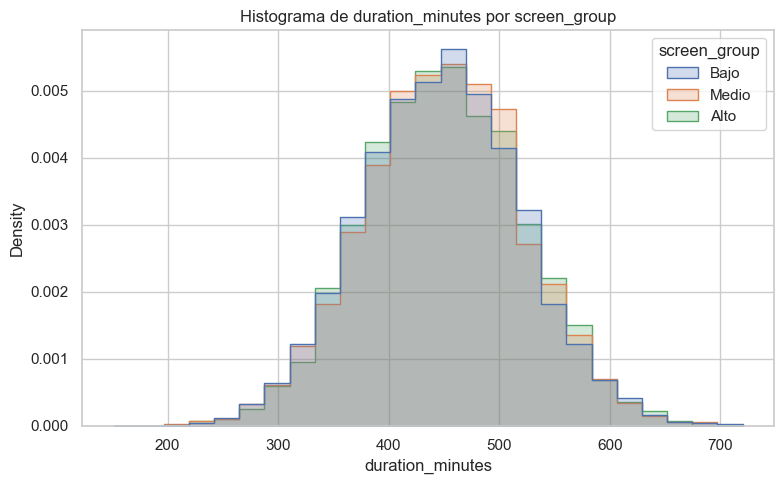

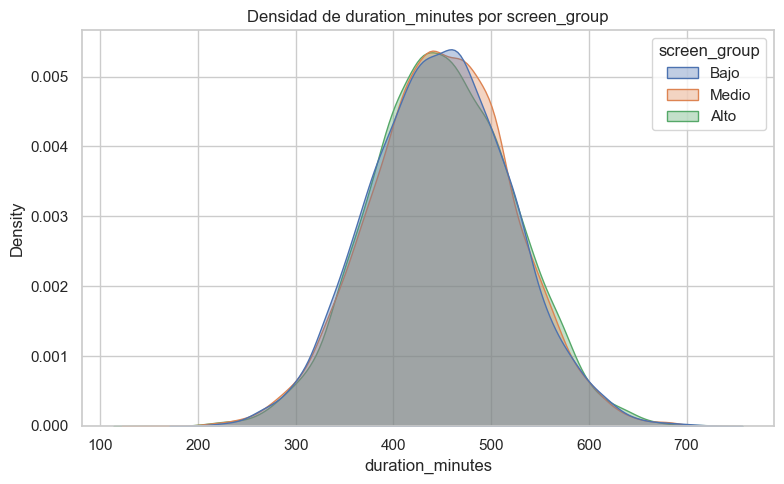

In [50]:
# =========================================================
# 10. HISTOGRAMAS Y DENSIDADES POR GRUPO
# =========================================================
for dv in dependent_vars:
    for factor in ["caffeine_group", "stress_group", "screen_group"]:
        plt.figure(figsize=(8, 5))
        sns.histplot(
            data=df_model,
            x=dv,
            hue=factor,
            stat="density",
            common_norm=False,
            element="step",
            bins=25
        )
        plt.title(f"Histograma de {dv} por {factor}")
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(8, 5))
        sns.kdeplot(
            data=df_model,
            x=dv,
            hue=factor,
            fill=True,
            common_norm=False,
            alpha=0.35
        )
        plt.title(f"Densidad de {dv} por {factor}")
        plt.tight_layout()
        plt.show()

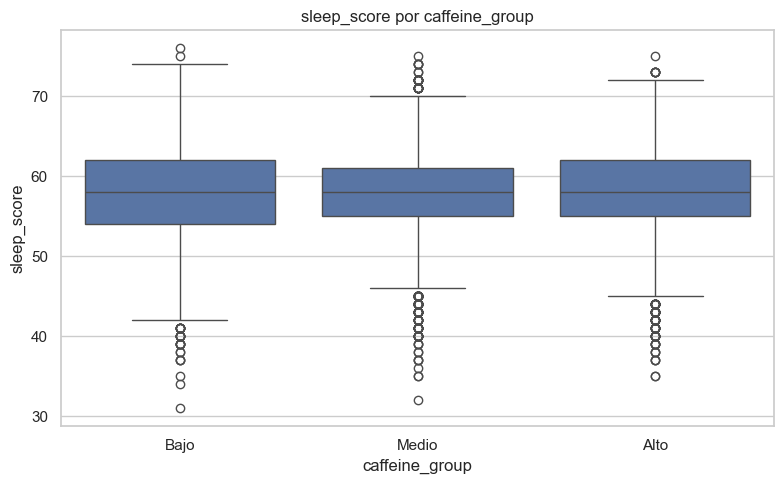

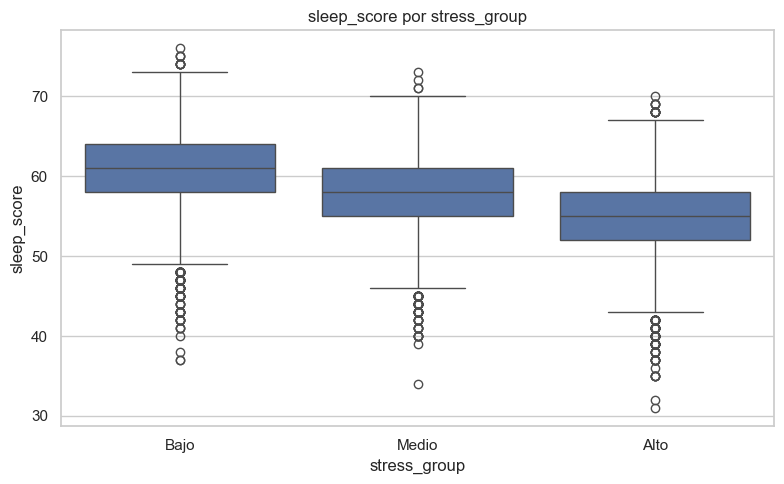

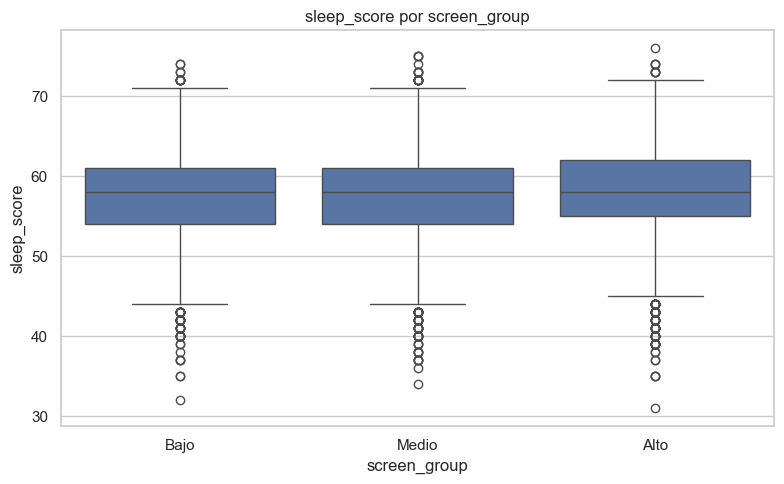

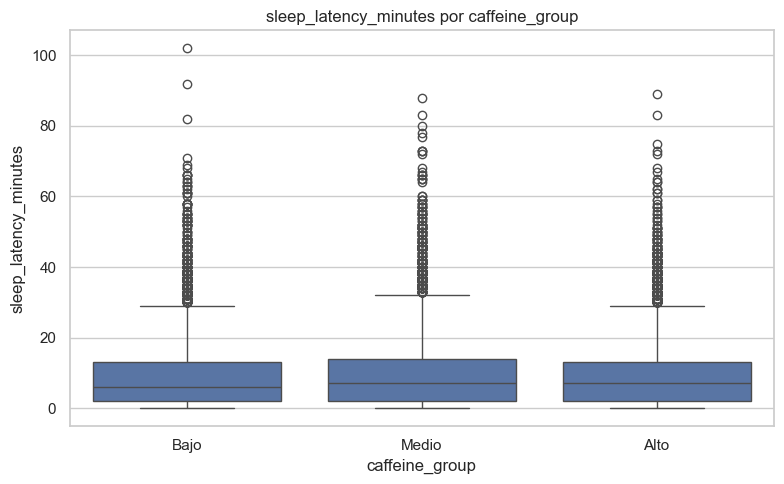

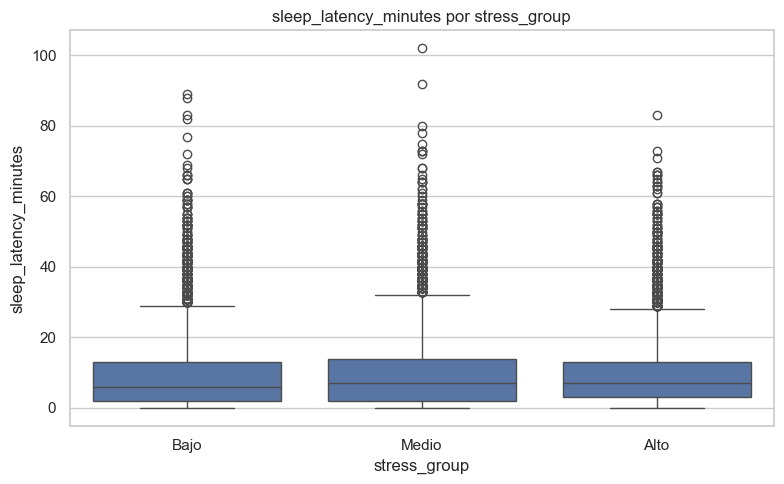

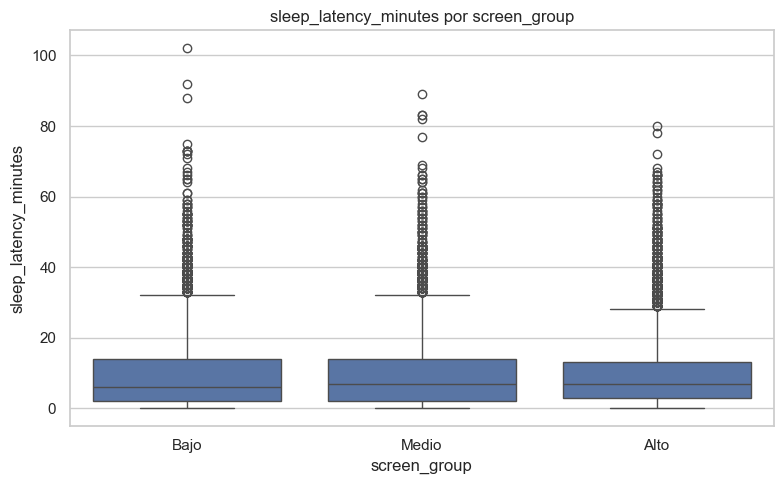

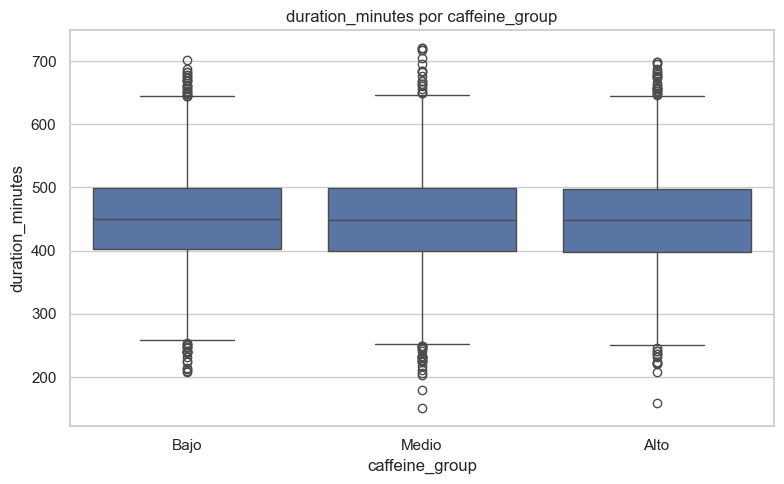

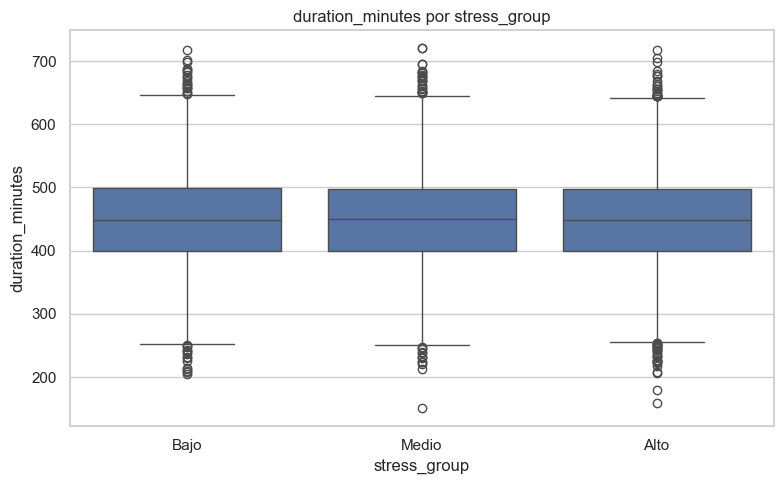

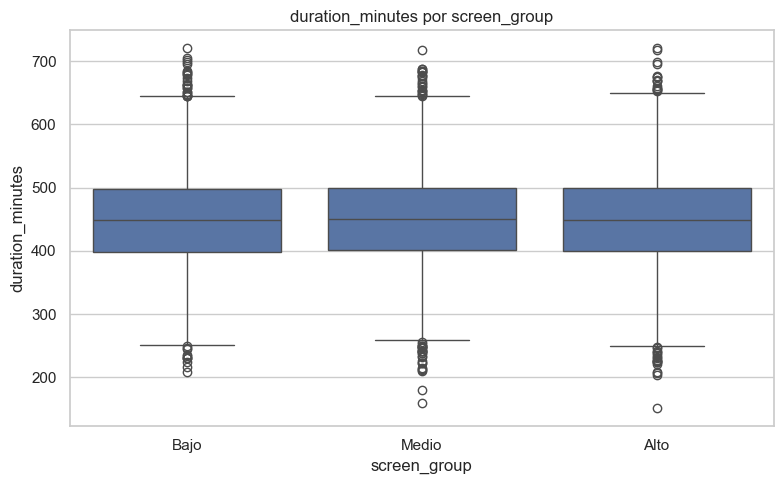

In [51]:
# =========================================================
# 11. BOXPLOTS AGRUPADOS
# =========================================================
for dv in dependent_vars:
    for factor in ["caffeine_group", "stress_group", "screen_group"]:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df_model, x=factor, y=dv)
        plt.title(f"{dv} por {factor}")
        plt.tight_layout()
        plt.show()

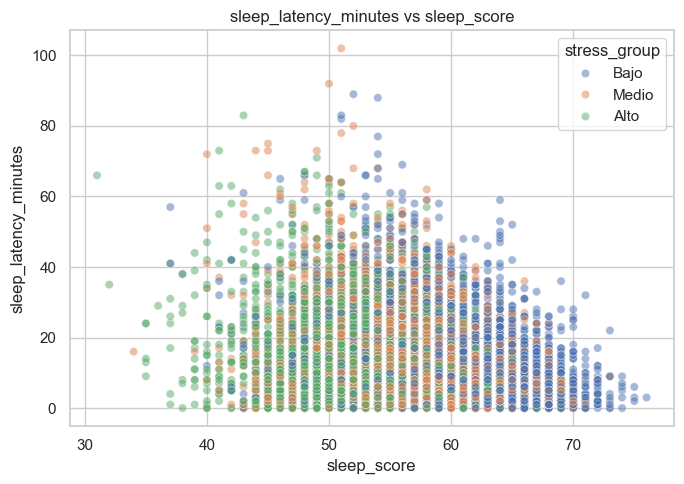

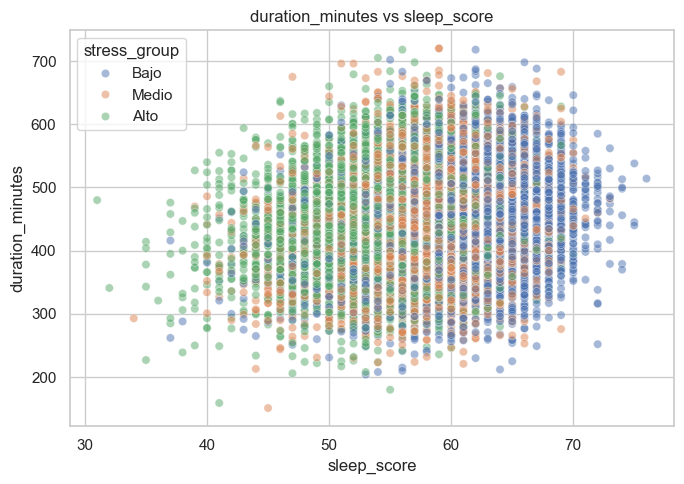

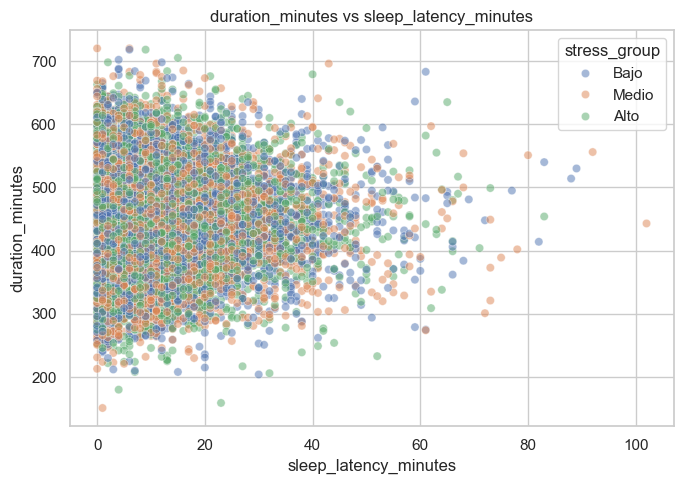

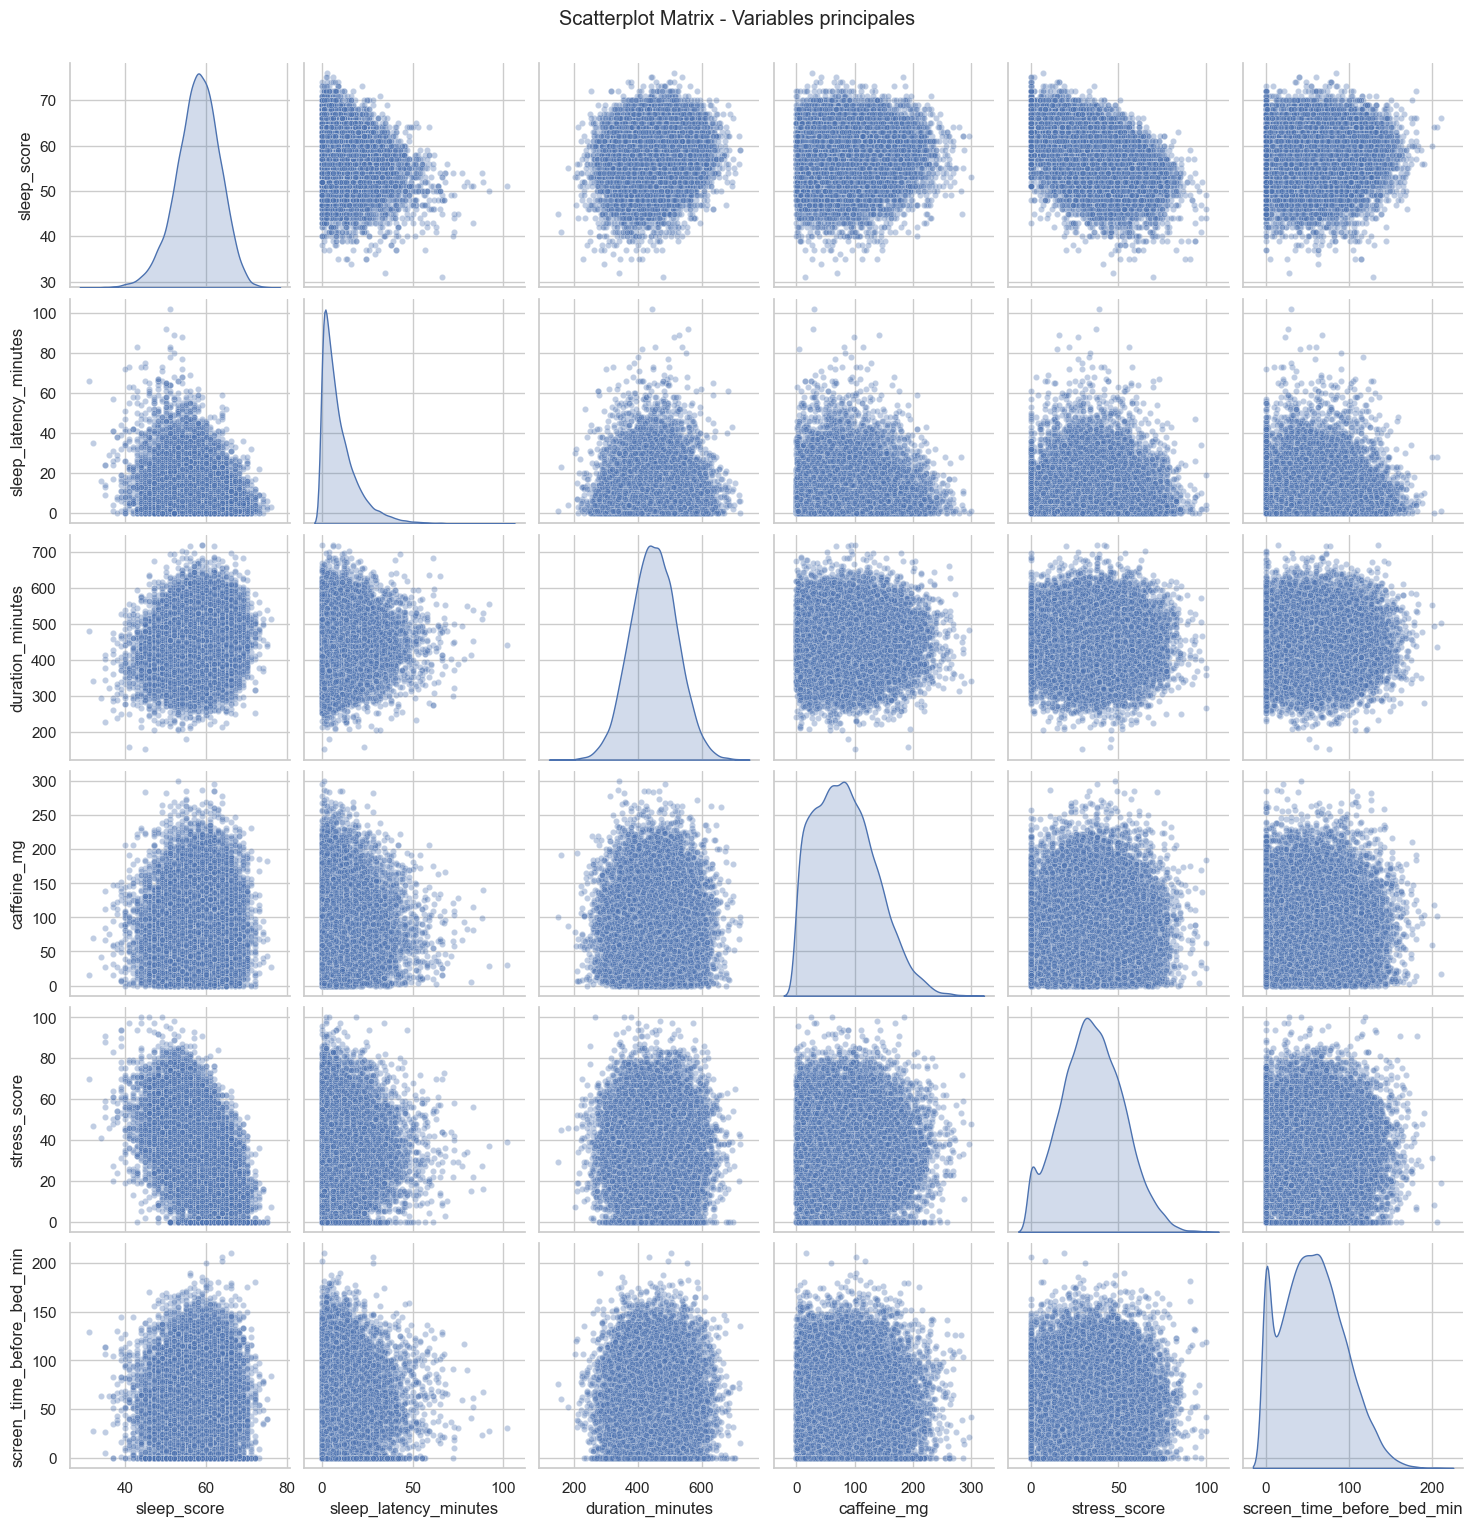

In [52]:
# =========================================================
# 12. SCATTERPLOTS Y SPLOM
# =========================================================
# Scatterplots simples entre dependientes
pairs = [
    ("sleep_score", "sleep_latency_minutes"),
    ("sleep_score", "duration_minutes"),
    ("sleep_latency_minutes", "duration_minutes")
]

for xvar, yvar in pairs:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        data=df_model,
        x=xvar,
        y=yvar,
        hue="stress_group",
        alpha=0.5
    )
    plt.title(f"{yvar} vs {xvar}")
    plt.tight_layout()
    plt.show()

# Scatterplot matrix de las variables principales
sns.pairplot(
    df_model[dependent_vars + independent_vars_cont],
    diag_kind="kde",
    plot_kws={"alpha": 0.35, "s": 20}
)
plt.suptitle("Scatterplot Matrix - Variables principales", y=1.02)
plt.show()

In [53]:
# =========================================================
# 13. MATRIZ DE VARIANZAS-COVARIANZAS Y CORRELACIONES
# =========================================================
cov_matrix = df_model[dependent_vars + independent_vars_cont].cov()
corr_matrix = df_model[dependent_vars + independent_vars_cont].corr()

print("Matriz de varianzas-covarianzas")
display(cov_matrix.round(3))

print("Matriz de correlaciones")
display(corr_matrix.round(3))

Matriz de varianzas-covarianzas


,sleep_score,sleep_latency_minutes,duration_minutes,caffeine_mg,stress_score,screen_time_before_bed_min
sleep_score,28.822,-14.872,53.653,0.921,-45.888,0.563
sleep_latency_minutes,-14.872,103.458,-4.791,-2.822,-0.073,2.338
duration_minutes,53.653,-4.791,5167.370,-32.945,-6.768,36.176
caffeine_mg,0.921,-2.822,-32.945,2713.031,3.374,1.329
stress_score,-45.888,-0.073,-6.768,3.374,305.916,-0.414
screen_time_before_bed_min,0.563,2.338,36.176,1.329,-0.414,1365.916


Matriz de correlaciones


,sleep_score,sleep_latency_minutes,duration_minutes,caffeine_mg,stress_score,screen_time_before_bed_min
sleep_score,1.000,-0.272,0.139,0.003,-0.489,0.003
sleep_latency_minutes,-0.272,1.000,-0.007,-0.005,-0.000,0.006
duration_minutes,0.139,-0.007,1.000,-0.009,-0.005,0.014
caffeine_mg,0.003,-0.005,-0.009,1.000,0.004,0.001
stress_score,-0.489,-0.000,-0.005,0.004,1.000,-0.001
screen_time_before_bed_min,0.003,0.006,0.014,0.001,-0.001,1.000


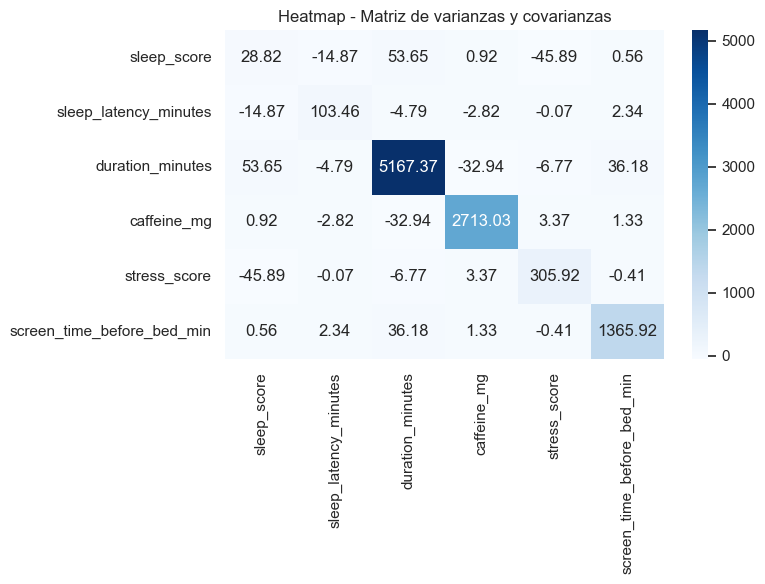

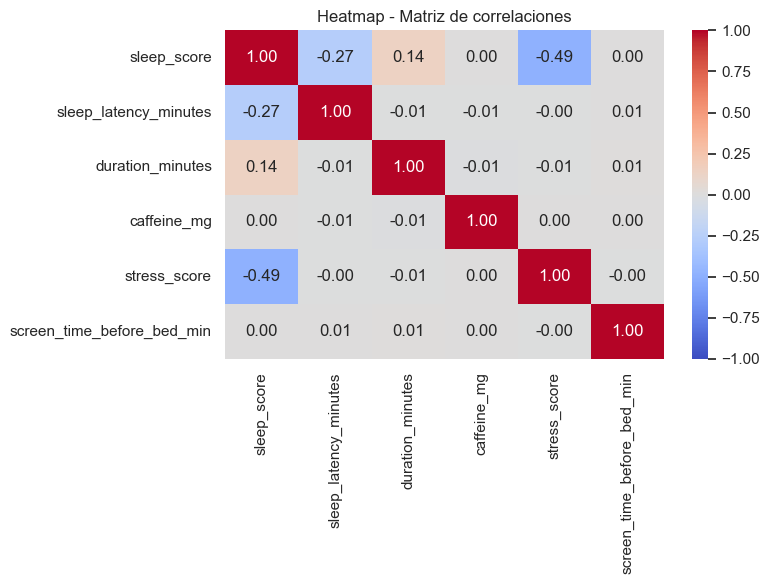

In [54]:
# =========================================================
# 14. HEATMAPS: COVARIANZA Y CORRELACIÓN
# =========================================================
plt.figure(figsize=(8, 6))
sns.heatmap(cov_matrix, annot=True, fmt=".2f", cmap="Blues")
plt.title("Heatmap - Matriz de varianzas y covarianzas")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Heatmap - Matriz de correlaciones")
plt.tight_layout()
plt.show()

In [55]:
# =========================================================
# 15. COMPARACIÓN: COVARIANZA VS CORRELACIÓN
# =========================================================
comparacion_cov_corr = pd.DataFrame({
    "Varianza (diagonal cov)": np.diag(cov_matrix),
    "Correlación consigo misma": np.diag(corr_matrix)
}, index=cov_matrix.index)

display(comparacion_cov_corr.round(3))

print("""
Interpretación base:
- La covarianza depende de la escala original de las variables.
- La correlación estandariza la relación y siempre queda entre -1 y 1.
- Por eso, la correlación permite comparar fuerza de asociación entre variables con distintas unidades.
""")

,Varianza (diagonal cov),Correlación consigo misma
sleep_score,28.822,1.0
sleep_latency_minutes,103.458,1.0
duration_minutes,5167.370,1.0
caffeine_mg,2713.031,1.0
stress_score,305.916,1.0
screen_time_before_bed_min,1365.916,1.0



Interpretación base:
- La covarianza depende de la escala original de las variables.
- La correlación estandariza la relación y siempre queda entre -1 y 1.
- Por eso, la correlación permite comparar fuerza de asociación entre variables con distintas unidades.



In [56]:
# =========================================================
# 16. MEDIA MULTIVARIANTE
# =========================================================
media_multivariante = df_model[dependent_vars].mean()
print("Vector de medias multivariante (variables dependientes):")
display(media_multivariante.round(3))

Vector de medias multivariante (variables dependientes):


sleep_score               57.862
sleep_latency_minutes      9.660
duration_minutes         449.189
dtype: float64

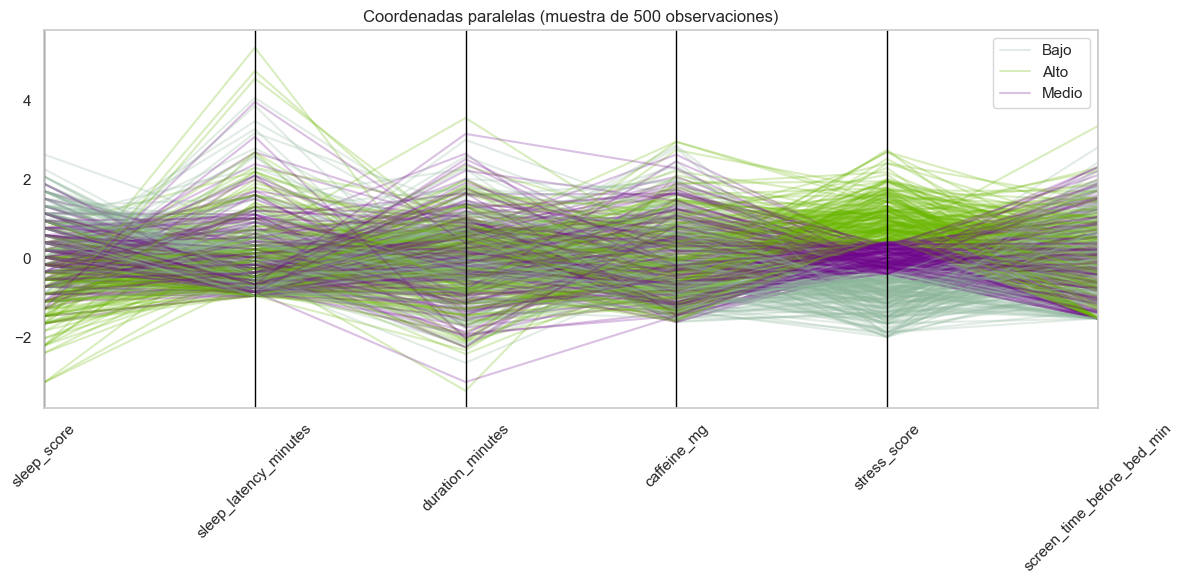

In [57]:
# =========================================================
# 17. COORDENADAS PARALELAS
# =========================================================
from pandas.plotting import parallel_coordinates
from sklearn.preprocessing import StandardScaler

vars_parallel = dependent_vars + independent_vars_cont

scaler = StandardScaler()
scaled_data = pd.DataFrame(
    scaler.fit_transform(df_model[vars_parallel]),
    columns=vars_parallel
)

scaled_data["stress_group"] = df_model["stress_group"].values

plt.figure(figsize=(12, 6))
parallel_coordinates(
    scaled_data.sample(500, random_state=42),
    class_column="stress_group",
    alpha=0.25
)
plt.title("Coordenadas paralelas (muestra de 500 observaciones)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_14792\3127108599.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  radar_means = df_model.groupby("stress_group")[vars_radar].mean()


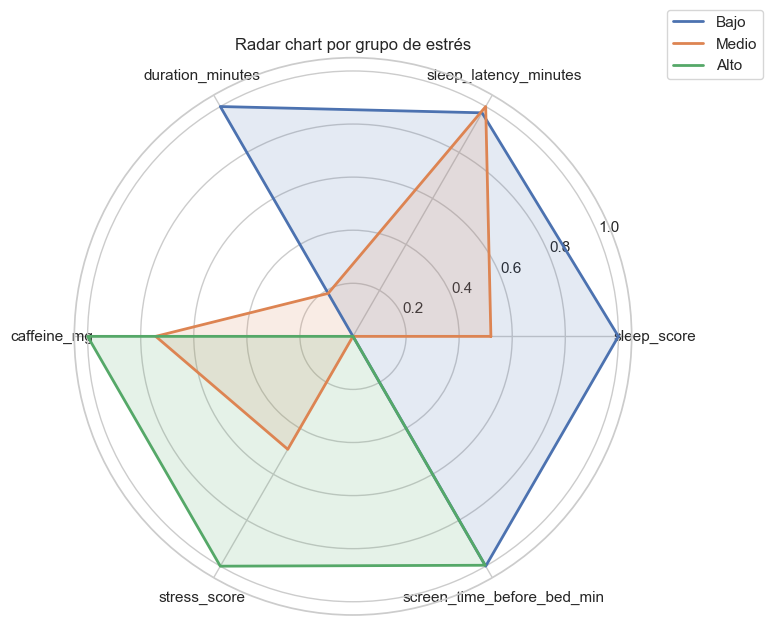

In [58]:
# =========================================================
# 18. RADAR CHART
# =========================================================
from sklearn.preprocessing import MinMaxScaler

vars_radar = dependent_vars + independent_vars_cont

radar_means = df_model.groupby("stress_group")[vars_radar].mean()

scaler = MinMaxScaler()
radar_scaled = pd.DataFrame(
    scaler.fit_transform(radar_means),
    index=radar_means.index,
    columns=radar_means.columns
)

num_vars = len(vars_radar)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for grupo in radar_scaled.index:
    values = radar_scaled.loc[grupo].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=grupo)
    ax.fill(angles, values, alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(vars_radar)
ax.set_title("Radar chart por grupo de estrés")
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1))
plt.tight_layout()
plt.show()

In [59]:
# =========================================================
# 19. NORMALIDAD UNIVARIADA
# =========================================================
# OJO: con n grande, Shapiro detecta desviaciones pequeñas.
# Se reporta junto con histogramas, Q-Q plots y forma de la distribución.

normalidad_uni = []

for var in dependent_vars + independent_vars_cont:
    stat_shapiro, p_shapiro = stats.shapiro(df_model[var].sample(5000, random_state=42))
    normalidad_uni.append({
        "variable": var,
        "Shapiro_W": stat_shapiro,
        "p_value": p_shapiro
    })

normalidad_uni = pd.DataFrame(normalidad_uni)
display(normalidad_uni.round(6))

,variable,Shapiro_W,p_value
0,sleep_score,0.991013,0.000000
1,sleep_latency_minutes,0.804987,0.000000
2,duration_minutes,0.999783,0.919034
3,caffeine_mg,0.971968,0.000000
4,stress_score,0.993731,0.000000
5,screen_time_before_bed_min,0.972303,0.000000


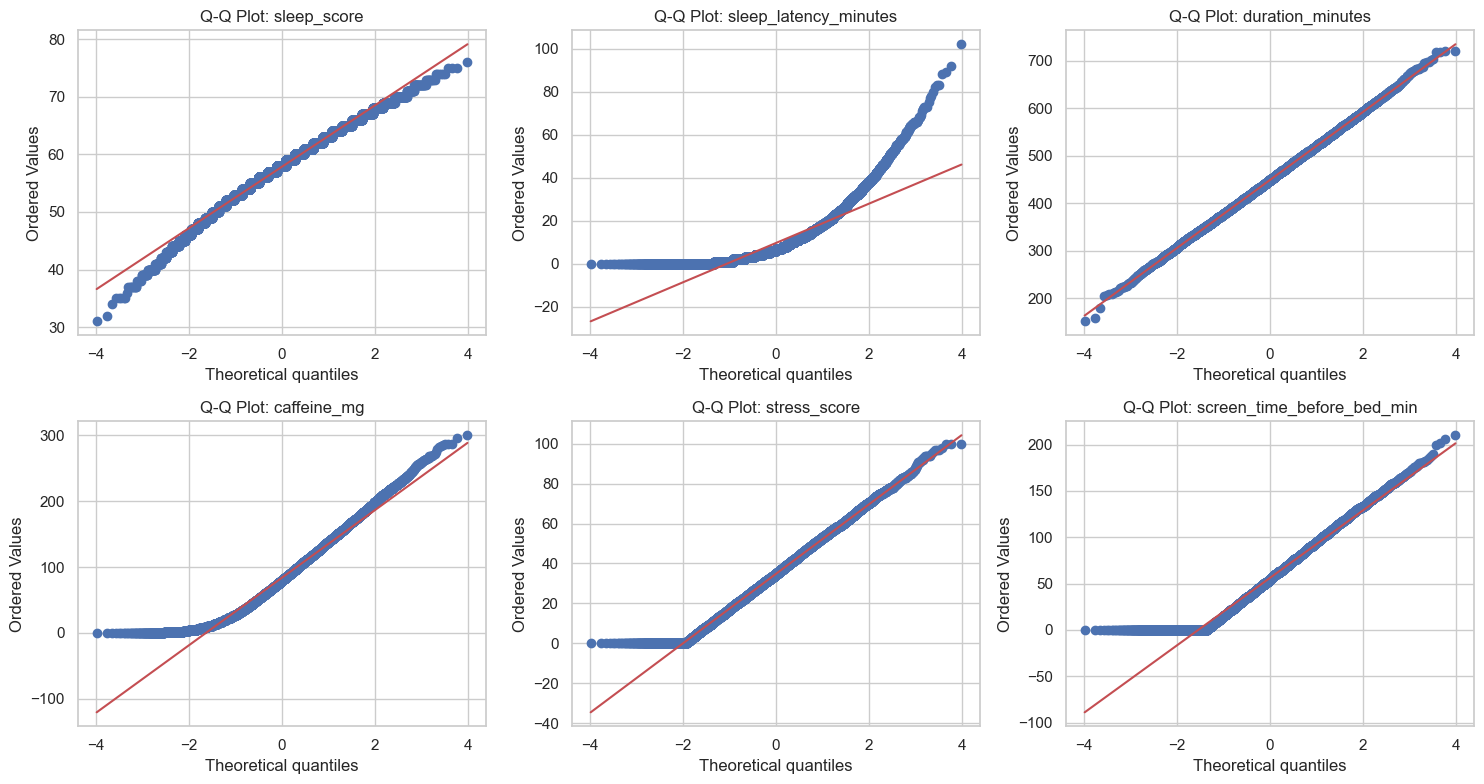

In [60]:
# =========================================================
# 20. Q-Q PLOTS UNIVARIADOS
# =========================================================
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, var in enumerate(dependent_vars + independent_vars_cont):
    stats.probplot(df_model[var], dist="norm", plot=axes[i])
    axes[i].set_title(f"Q-Q Plot: {var}")

plt.tight_layout()
plt.show()

In [61]:
# =========================================================
# 21. NORMALIDAD MULTIVARIADA - HENZE ZIRKLER
# =========================================================
# La evaluamos sobre las variables dependientes del MANOVA
hz_result = pg.multivariate_normality(df_model[dependent_vars], alpha=0.05)
print(hz_result)

HZResults(hz=np.float64(19103.874490707898), pval=np.float64(0.0), normal=False)


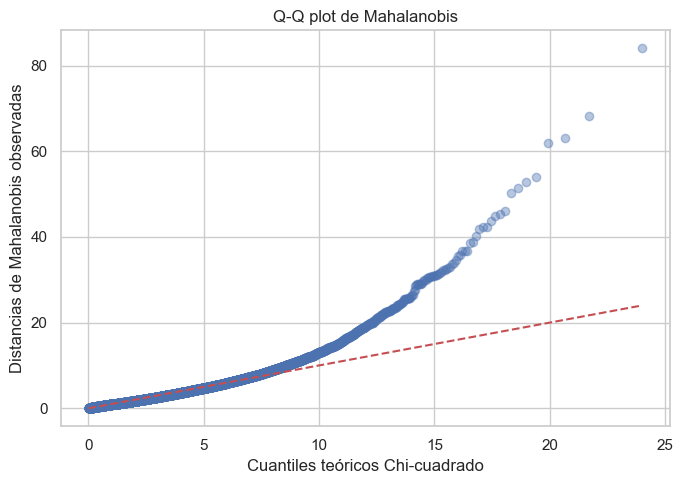

In [62]:
# =========================================================
# 22. Q-Q PLOT DE DISTANCIAS DE MAHALANOBIS
# =========================================================
X = df_model[dependent_vars].values
n, p = X.shape

mean_vec = X.mean(axis=0)
cov_mat = np.cov(X, rowvar=False)
inv_cov_mat = np.linalg.inv(cov_mat)

d2 = np.array([
    distance.mahalanobis(x, mean_vec, inv_cov_mat)**2 for x in X
])

q = stats.chi2.ppf((np.arange(1, n + 1) - 0.5) / n, df=p)

plt.figure(figsize=(7, 5))
plt.scatter(np.sort(q), np.sort(d2), alpha=0.4)
plt.plot(np.sort(q), np.sort(q), "r--")
plt.xlabel("Cuantiles teóricos Chi-cuadrado")
plt.ylabel("Distancias de Mahalanobis observadas")
plt.title("Q-Q plot de Mahalanobis")
plt.tight_layout()
plt.show()

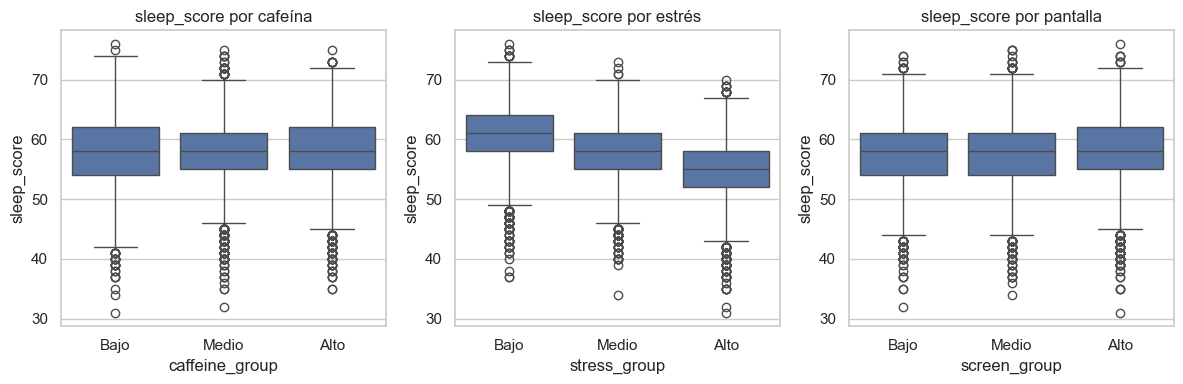

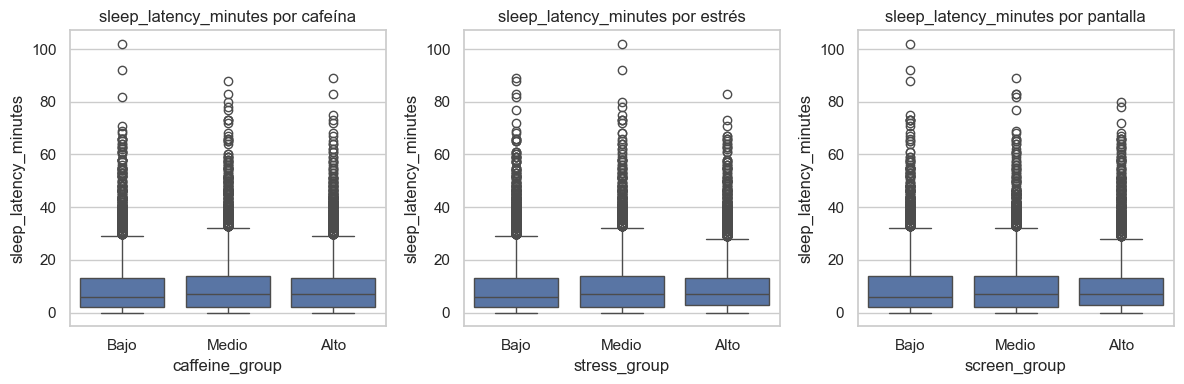

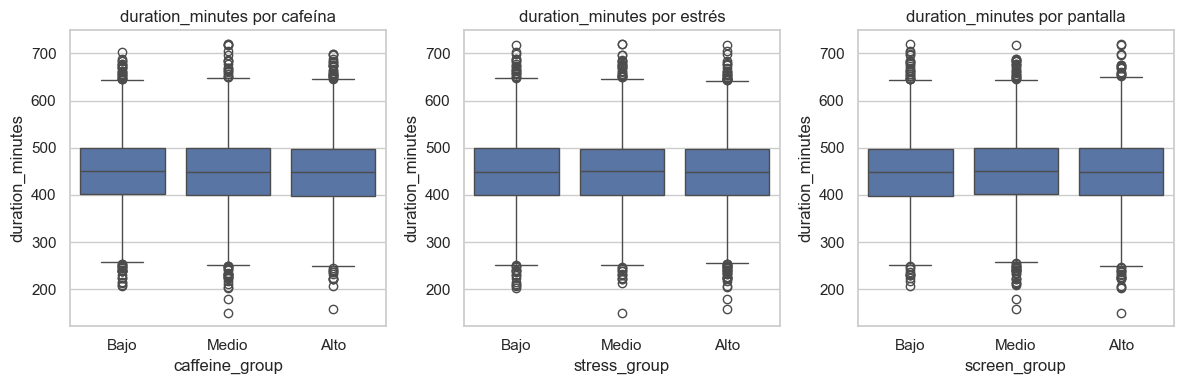

In [63]:
# =========================================================
# 23. BOXPLOTS COMO APOYO A NORMALIDAD MULTIVARIADA
# =========================================================
for dv in dependent_vars:
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    sns.boxplot(data=df_model, x="caffeine_group", y=dv)
    plt.title(f"{dv} por cafeína")

    plt.subplot(1, 3, 2)
    sns.boxplot(data=df_model, x="stress_group", y=dv)
    plt.title(f"{dv} por estrés")

    plt.subplot(1, 3, 3)
    sns.boxplot(data=df_model, x="screen_group", y=dv)
    plt.title(f"{dv} por pantalla")

    plt.tight_layout()
    plt.show()

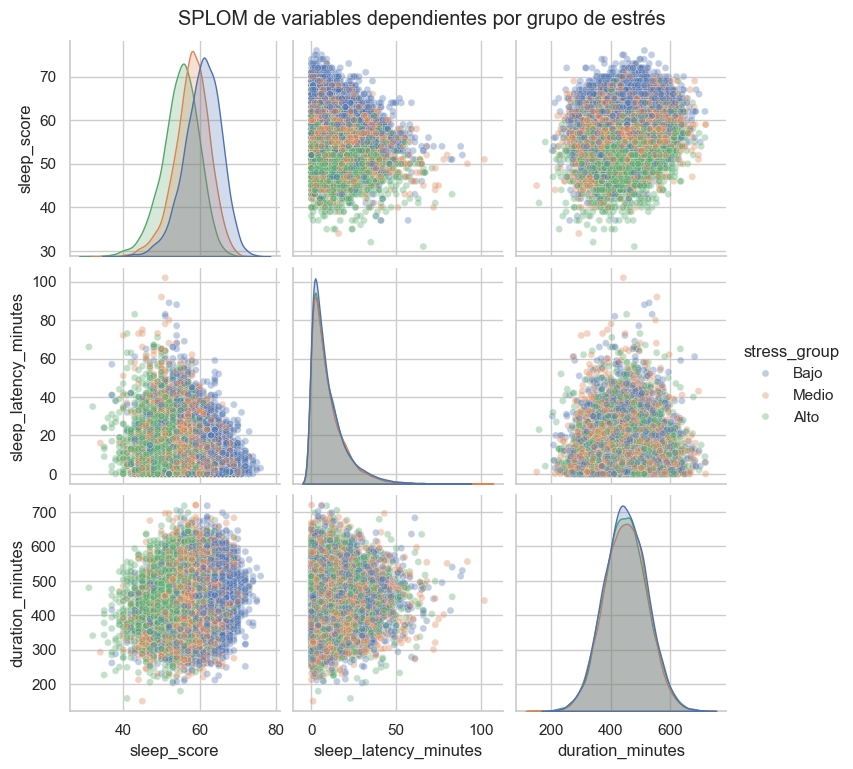

In [64]:
# =========================================================
# 24. SCATTERPLOTS MULTIVARIADOS DE APOYO
# =========================================================
sns.pairplot(
    df_model[dependent_vars + ["stress_group"]],
    hue="stress_group",
    diag_kind="kde",
    plot_kws={"alpha": 0.35, "s": 25}
)
plt.suptitle("SPLOM de variables dependientes por grupo de estrés", y=1.02)
plt.show()

In [65]:
# =========================================================
# 25. HOMOGENEIDAD DE MATRICES DE COVARIANZA - BOX'S M
# =========================================================
# Se usa el grupo combinado de los 3 factores
df_boxm = df_model[dependent_vars + ["combined_group"]].dropna()

box_m_result = pg.box_m(
    data=df_boxm,
    dvs=dependent_vars,
    group="combined_group"
)

display(box_m_result)

,Chi2,df,pval,equal_cov
box,271.342002,156.0,2.975254e-08,False


In [66]:
# =========================================================
# 26. MANOVA DE 3 VÍAS
# =========================================================
formula_manova = """
sleep_score + sleep_latency_minutes + duration_minutes
~ C(caffeine_group) * C(stress_group) * C(screen_group)
"""

manova = MANOVA.from_formula(formula_manova, data=df_model)
print(manova.mv_test())

                                 Multivariate linear model
                                                                                           
------------------------------------------------------------------------------------------------
            Intercept             Value       Num DF        Den DF         F Value        Pr > F
------------------------------------------------------------------------------------------------
               Wilks' lambda      0.1113      3.0000      19971.0000      53144.6647      0.0000
              Pillai's trace      0.8887      3.0000      19971.0000      53144.6647      0.0000
      Hotelling-Lawley trace      7.9833      3.0000      19971.0000      53144.6647      0.0000
         Roy's greatest root      7.9833      3.0000      19971.0000      53144.6647      0.0000
-------------------------------------------------------------------------------------------
                                                                              

In [67]:
# =========================================================
# 27. ANOVAS DE 3 VÍAS
# =========================================================
# Una por cada variable dependiente

formula_sleep_score = """
sleep_score ~ C(caffeine_group) * C(stress_group) * C(screen_group)
"""

formula_latency = """
sleep_latency_minutes ~ C(caffeine_group) * C(stress_group) * C(screen_group)
"""

formula_duration = """
duration_minutes ~ C(caffeine_group) * C(stress_group) * C(screen_group)
"""

model_sleep_score = smf.ols(formula_sleep_score, data=df_model).fit()
model_latency = smf.ols(formula_latency, data=df_model).fit()
model_duration = smf.ols(formula_duration, data=df_model).fit()

anova_sleep_score = sm.stats.anova_lm(model_sleep_score, typ=2)
anova_latency = sm.stats.anova_lm(model_latency, typ=2)
anova_duration = sm.stats.anova_lm(model_duration, typ=2)

print("ANOVA 3 vías - sleep_score")
display(anova_sleep_score)

print("ANOVA 3 vías - sleep_latency_minutes")
display(anova_latency)

print("ANOVA 3 vías - duration_minutes")
display(anova_duration)

ANOVA 3 vías - sleep_score


,sum_sq,df,F,PR(>F)
C(caffeine_group),11.632332,2.0,0.250067,0.778751
C(stress_group),111334.483288,2.0,2393.423293,0.000000
C(screen_group),7.553282,2.0,0.162377,0.850121
C(caffeine_group):C(stress_group),74.088241,4.0,0.796359,0.527302
C(caffeine_group):C(screen_group),65.964655,4.0,0.709041,0.585617
C(stress_group):C(screen_group),187.465674,4.0,2.015030,0.089444
C(caffeine_group):C(stress_group):C(screen_group),185.759986,8.0,0.998348,0.434801
Residual,464540.401367,19973.0,NaN,NaN


ANOVA 3 vías - sleep_latency_minutes


,sum_sq,df,F,PR(>F)
C(caffeine_group),3.569282e+02,2.0,1.725881,0.178043
C(stress_group),7.580302e+00,2.0,0.036654,0.964010
C(screen_group),2.394283e+01,2.0,0.115772,0.890678
C(caffeine_group):C(stress_group),2.607086e+02,4.0,0.630312,0.640841
C(caffeine_group):C(screen_group),1.184441e+03,4.0,2.863607,0.021930
C(stress_group):C(screen_group),9.071994e+02,4.0,2.193324,0.067063
C(caffeine_group):C(stress_group):C(screen_group),1.008341e+03,8.0,1.218926,0.282977
Residual,2.065301e+06,19973.0,NaN,NaN


ANOVA 3 vías - duration_minutes


,sum_sq,df,F,PR(>F)
C(caffeine_group),1.104135e+04,2.0,1.068321,0.343604
C(stress_group),1.771955e+03,2.0,0.171448,0.842445
C(screen_group),1.374733e+04,2.0,1.330143,0.264463
C(caffeine_group):C(stress_group),3.753358e+04,4.0,1.815808,0.122660
C(caffeine_group):C(screen_group),7.974673e+03,4.0,0.385801,0.818959
C(stress_group):C(screen_group),6.553735e+03,4.0,0.317058,0.866738
C(caffeine_group):C(stress_group):C(screen_group),5.088808e+04,8.0,1.230937,0.275962
Residual,1.032128e+08,19973.0,NaN,NaN



===== sleep_score =====
Shapiro residuos: ShapiroResult(statistic=np.float64(0.9875153635665449), pvalue=np.float64(1.2400238896349143e-20))


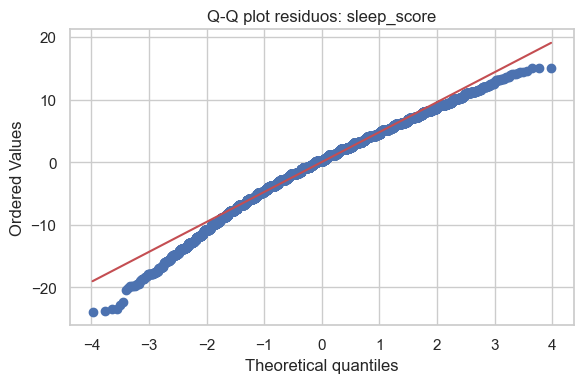


===== sleep_latency_minutes =====
Shapiro residuos: ShapiroResult(statistic=np.float64(0.8094994233452901), pvalue=np.float64(1.1310527713856775e-60))


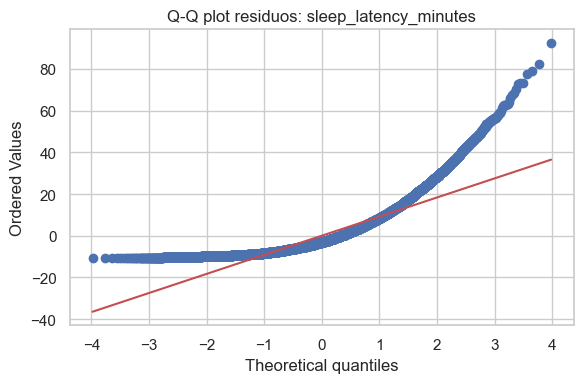


===== duration_minutes =====
Shapiro residuos: ShapiroResult(statistic=np.float64(0.9998032819431542), pvalue=np.float64(0.9506270353005705))


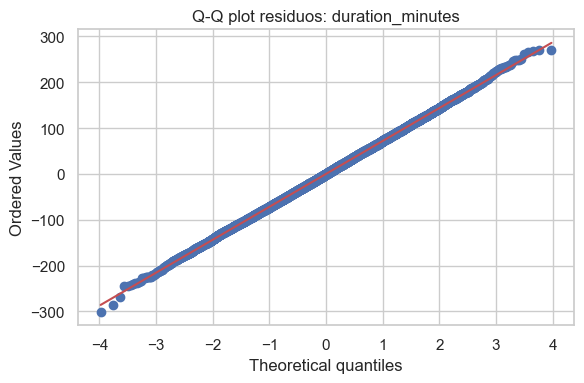

In [68]:
# =========================================================
# 28. SUPUESTOS DE LOS ANOVAS: NORMALIDAD DE RESIDUOS
# =========================================================
residuos = {
    "sleep_score": model_sleep_score.resid,
    "sleep_latency_minutes": model_latency.resid,
    "duration_minutes": model_duration.resid
}

for name, resid in residuos.items():
    print(f"\n===== {name} =====")
    
    # Shapiro sobre muestra de residuos
    shapiro_res = stats.shapiro(pd.Series(resid).sample(5000, random_state=42))
    print("Shapiro residuos:", shapiro_res)
    
    # Q-Q plot
    plt.figure(figsize=(6, 4))
    stats.probplot(resid, dist="norm", plot=plt)
    plt.title(f"Q-Q plot residuos: {name}")
    plt.tight_layout()
    plt.show()

In [69]:
# =========================================================
# 29. SUPUESTOS DE LOS ANOVAS: HOMOCEDASTICIDAD
# =========================================================
# Levene por grupo combinado

for dv in dependent_vars:
    grupos_levene = [
        grupo[dv].values
        for _, grupo in df_model.groupby("combined_group")
    ]
    
    stat_lev, p_lev = stats.levene(*grupos_levene)
    print(f"{dv} -> Levene stat={stat_lev:.4f}, p={p_lev:.6f}")

sleep_score -> Levene stat=1.8576, p=0.005029
sleep_latency_minutes -> Levene stat=1.3622, p=0.103141
duration_minutes -> Levene stat=0.8251, p=0.718121


In [70]:
# =========================================================
# 30. POST-HOC
# =========================================================
# Se recomienda hacerlo para efectos principales significativos.
# Aquí te dejo el código listo para cada factor y cada variable dependiente.

factores = ["caffeine_group", "stress_group", "screen_group"]

for dv in dependent_vars:
    print(f"\n\n================ POST-HOC PARA {dv} ================\n")
    for factor in factores:
        print(f"\n--- Tukey para {factor} ---")
        tukey = pairwise_tukeyhsd(
            endog=df_model[dv],
            groups=df_model[factor],
            alpha=0.05
        )
        print(tukey)



================ POST-HOC PARA sleep_score ================


--- Tukey para caffeine_group ---
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
  Alto   Bajo  -0.0401 0.9031 -0.2584 0.1783  False
  Alto  Medio  -0.0553 0.8231 -0.2734 0.1627  False
  Bajo  Medio  -0.0152 0.9853 -0.2327 0.2022  False
---------------------------------------------------

--- Tukey para stress_group ---
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
  Alto   Bajo   5.7476   0.0  5.5529  5.9423   True
  Alto  Medio   2.9867   0.0  2.7891  3.1843   True
  Bajo  Medio  -2.7609   0.0 -2.9561 -2.5656   True
---------------------------------------------------

--- Tukey para screen_group ---
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
----

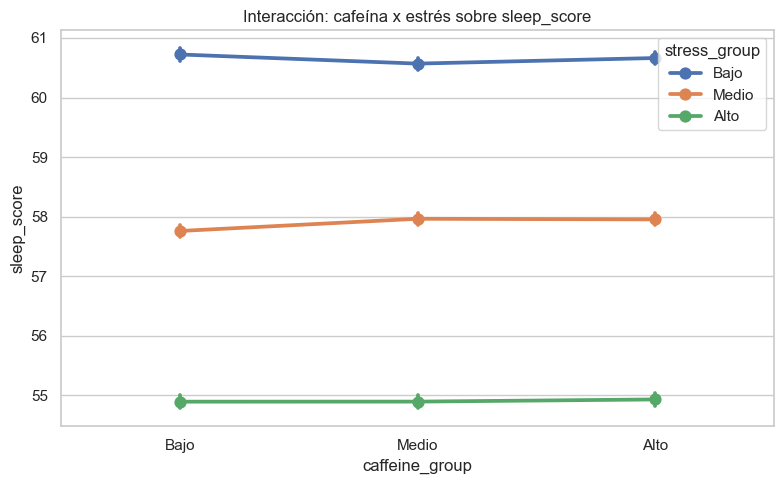

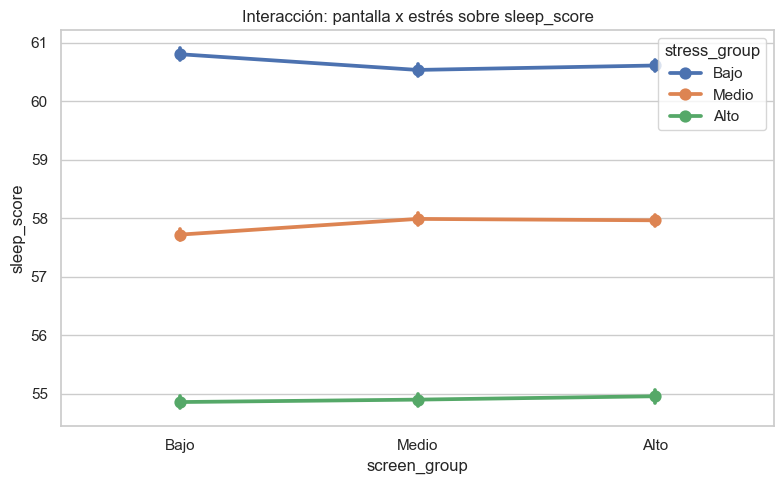

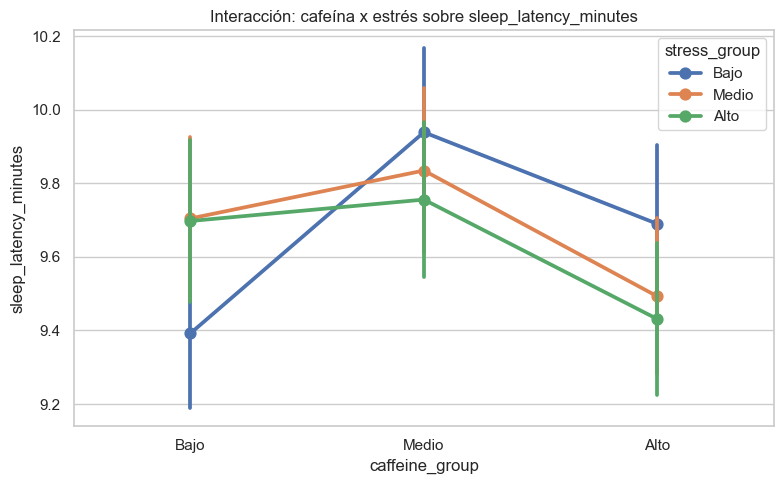

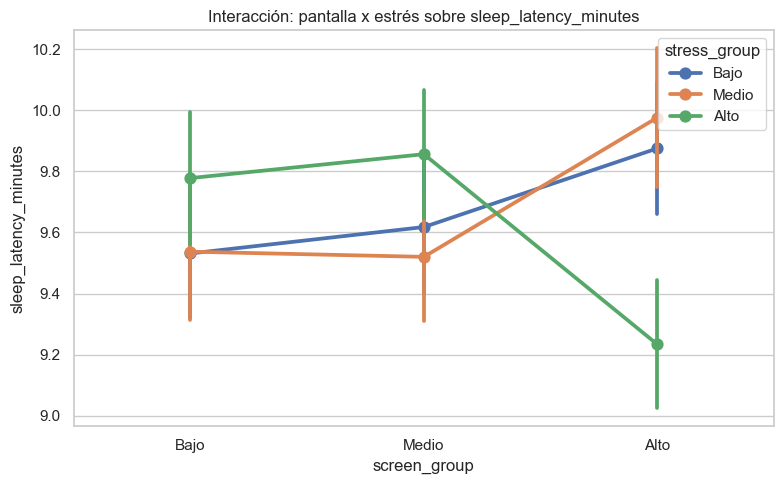

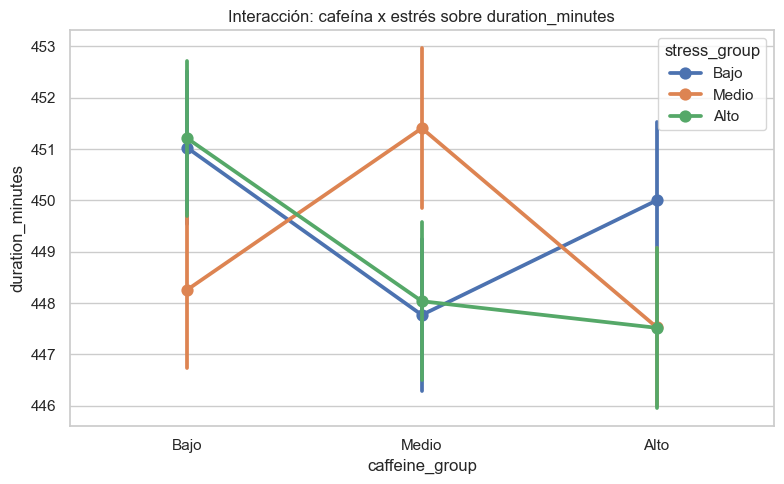

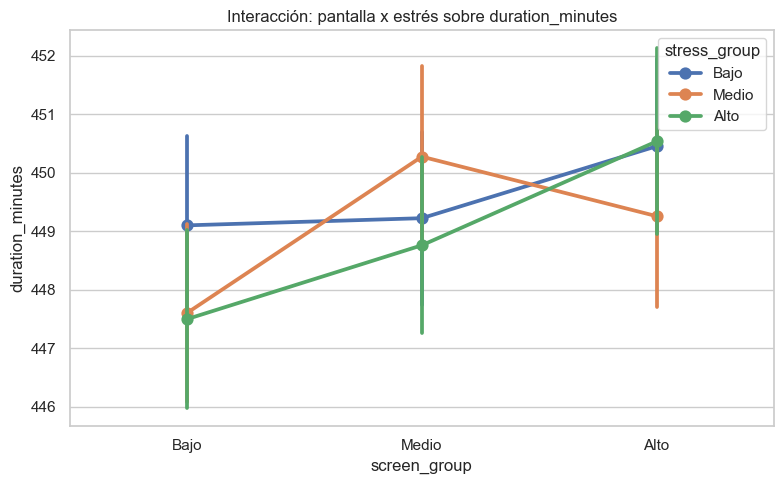

In [71]:
# =========================================================
# 31. GRÁFICOS DE INTERACCIÓN
# =========================================================
# Útiles para interpretar interacciones significativas

for dv in dependent_vars:
    plt.figure(figsize=(8, 5))
    sns.pointplot(
        data=df_model,
        x="caffeine_group",
        y=dv,
        hue="stress_group",
        errorbar="se"
    )
    plt.title(f"Interacción: cafeína x estrés sobre {dv}")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    sns.pointplot(
        data=df_model,
        x="screen_group",
        y=dv,
        hue="stress_group",
        errorbar="se"
    )
    plt.title(f"Interacción: pantalla x estrés sobre {dv}")
    plt.tight_layout()
    plt.show()

In [72]:
# =========================================================
# 32. TABLA RESUMEN DE RESULTADOS
# =========================================================
def resumen_anova(anova_table, nombre_variable):
    out = anova_table.reset_index().copy()
    out["variable_dependiente"] = nombre_variable
    return out.rename(columns={"index": "efecto"})

tabla_resumen = pd.concat([
    resumen_anova(anova_sleep_score, "sleep_score"),
    resumen_anova(anova_latency, "sleep_latency_minutes"),
    resumen_anova(anova_duration, "duration_minutes")
], ignore_index=True)

display(tabla_resumen)

,efecto,sum_sq,df,F,PR(>F),variable_dependiente
0,C(caffeine_group),1.163233e+01,2.0,0.250067,0.778751,sleep_score
1,C(stress_group),1.113345e+05,2.0,2393.423293,0.000000,sleep_score
2,C(screen_group),7.553282e+00,2.0,0.162377,0.850121,sleep_score
3,C(caffeine_group):C(stress_group),7.408824e+01,4.0,0.796359,0.527302,sleep_score
4,C(caffeine_group):C(screen_group),6.596465e+01,4.0,0.709041,0.585617,sleep_score
5,C(stress_group):C(screen_group),1.874657e+02,4.0,2.015030,0.089444,sleep_score
6,C(caffeine_group):C(stress_group):C(screen_group),1.857600e+02,8.0,0.998348,0.434801,sleep_score
7,Residual,4.645404e+05,19973.0,NaN,NaN,sleep_score
8,C(caffeine_group),3.569282e+02,2.0,1.725881,0.178043,sleep_latency_minutes
9,C(stress_group),7.580302e+00,2.0,0.036654,0.964010,sleep_latency_minutes


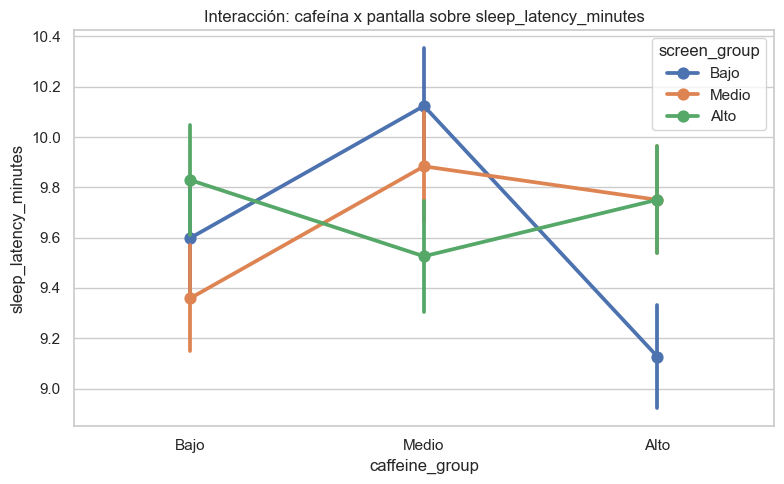

In [73]:
#interacción importante

plt.figure(figsize=(8,5))
sns.pointplot(
    data=df_model,
    x="caffeine_group",
    y="sleep_latency_minutes",
    hue="screen_group",
    errorbar="se"
)
plt.title("Interacción: cafeína x pantalla sobre sleep_latency_minutes")
plt.tight_layout()
plt.show()

Corriendo MANOVA por permutación: 9999 permutaciones × 7 términos
Estadístico: traza de Pillai

  [ 51.8s]  C(caffeine_group)                                        Pillai=0.000754  p_emp=0.0209
  [ 99.3s]  C(stress_group)                                          Pillai=0.030731  p_emp=0.0001
  [145.6s]  C(screen_group)                                          Pillai=0.000215  p_emp=0.6409
  [190.1s]  C(caffeine_group):C(stress_group)                        Pillai=0.000630  p_emp=0.3958
  [234.4s]  C(caffeine_group):C(screen_group)                        Pillai=0.001059  p_emp=0.0471
  [278.6s]  C(stress_group):C(screen_group)                          Pillai=0.000628  p_emp=0.4067
  [322.9s]  C(caffeine_group):C(stress_group):C(screen_group)        Pillai=0.001279  p_emp=0.3783

Tiempo total: 322.9s

--- Tabla 11. MANOVA paramétrico vs MANOVA por permutación (Pillai) ---


,Termino,Pillai_obs,p_parametrico,Pillai_perm_media,Pillai_perm_p95,p_permutacion,¿Convergen?
0,C(caffeine_group),0.00075,0.01980,0.00030,0.00064,0.0209,Sí
1,C(stress_group),0.03073,0.00000,0.00031,0.00065,0.0001,Sí
2,C(screen_group),0.00022,0.63618,0.00030,0.00064,0.6409,Sí
3,C(caffeine_group):C(stress_group),0.00063,0.39938,0.00060,0.00106,0.3958,Sí
4,C(caffeine_group):C(screen_group),0.00106,0.04812,0.00060,0.00105,0.0471,Sí
5,C(stress_group):C(screen_group),0.00063,0.40217,0.00060,0.00106,0.4067,Sí
6,C(caffeine_group):C(stress_group):C(screen_group),0.00128,0.37638,0.00120,0.00184,0.3783,Sí


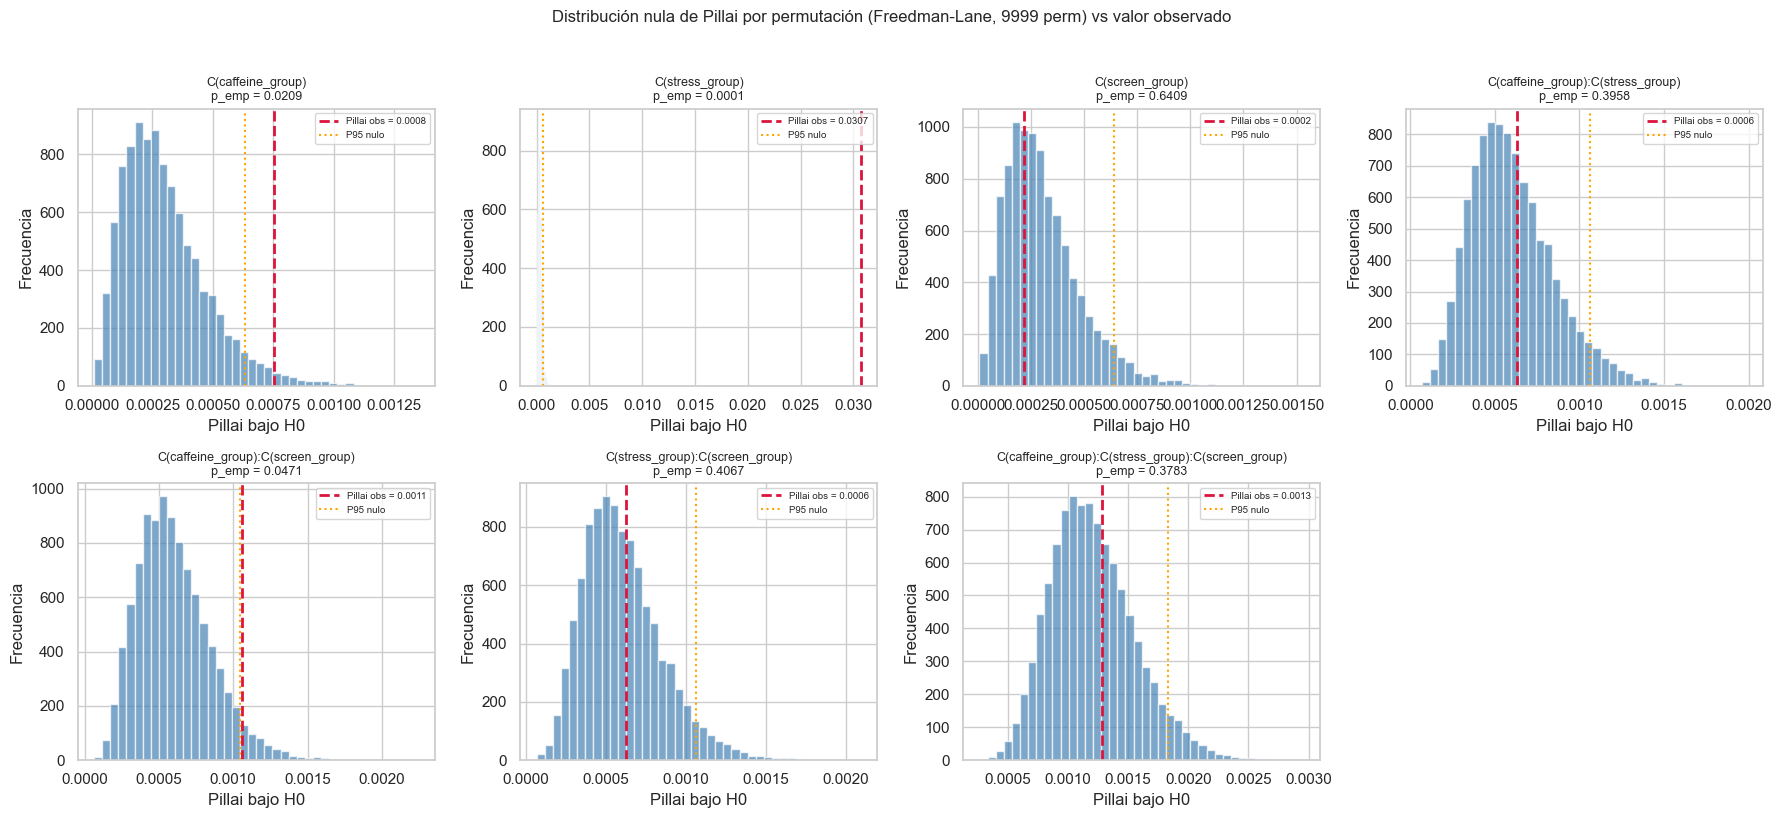

In [74]:
# =========================================================
# 34. PERMUTACIÓN-MANOVA DE 3 VÍAS (Freedman-Lane)
# =========================================================

from patsy import dmatrices
import time

# --- 34.1 Construcción de matrices Y, X_full y términos del modelo -----
formula_manova_full = (
    "sleep_score + sleep_latency_minutes + duration_minutes ~ "
    "C(caffeine_group) * C(stress_group) * C(screen_group)"
)

Y_df, X_df = dmatrices(formula_manova_full, data=df_model, return_type="dataframe")
Y_obs = np.asarray(Y_df)
X_full = np.asarray(X_df)
col_names = list(X_df.columns)

terms_manova = [
    "C(caffeine_group)",
    "C(stress_group)",
    "C(screen_group)",
    "C(caffeine_group):C(stress_group)",
    "C(caffeine_group):C(screen_group)",
    "C(stress_group):C(screen_group)",
    "C(caffeine_group):C(stress_group):C(screen_group)",
]


def _cols_of_term(term, col_names):
    """Identifica las columnas de la matriz de diseño que pertenecen
    EXACTAMENTE a un término del modelo (mismo nivel de interacción y
    todos los factores presentes)."""
    n_colons = term.count(":")
    cols = []
    for i, c in enumerate(col_names):
        if c == "Intercept":
            continue
        if c.count(":") != n_colons:
            continue
        if all(f in c for f in term.split(":")):
            cols.append(i)
    return cols


# --- 34.2 QR del modelo full y precómputo por término -------------------
Q_full, _ = np.linalg.qr(X_full)
fitted_full_obs = Q_full @ (Q_full.T @ Y_obs)
resid_full_obs = Y_obs - fitted_full_obs
E_obs = resid_full_obs.T @ resid_full_obs

term_cache = {}
for t in terms_manova:
    cols_T = _cols_of_term(t, col_names)
    keep = [i for i in range(X_full.shape[1]) if i not in cols_T]
    X_red = X_full[:, keep]
    Q_red, _ = np.linalg.qr(X_red)
    fitted_red = Q_red @ (Q_red.T @ Y_obs)
    resid_red = Y_obs - fitted_red
    term_cache[t] = {"Q_red": Q_red, "fitted_red": fitted_red, "resid_red": resid_red}


# --- 34.3 Loop de permutaciones ----------------------------------------
N_PERM = 9999
rng = np.random.default_rng(2024)

print(f"Corriendo MANOVA por permutación: {N_PERM} permutaciones × {len(terms_manova)} términos")
print("Estadístico: traza de Pillai\n")
t0 = time.time()

perm_records = []
pillai_dist = {}  # guardamos la distribución para el plot

for t in terms_manova:
    Q_red = term_cache[t]["Q_red"]
    fitted_red = term_cache[t]["fitted_red"]
    resid_red = term_cache[t]["resid_red"]

    # Pillai observado
    E_red_obs = resid_red.T @ resid_red
    H_obs = E_red_obs - E_obs
    pillai_obs = float(np.trace(np.linalg.solve(H_obs + E_obs, H_obs)))

    # Permutaciones
    pillai_perm = np.zeros(N_PERM)
    for k in range(N_PERM):
        perm = rng.permutation(Y_obs.shape[0])
        Y_star = fitted_red + resid_red[perm]

        resid_full_star = Y_star - Q_full @ (Q_full.T @ Y_star)
        E_star = resid_full_star.T @ resid_full_star

        resid_red_star = Y_star - Q_red @ (Q_red.T @ Y_star)
        E_red_star = resid_red_star.T @ resid_red_star

        H_star = E_red_star - E_star
        pillai_perm[k] = np.trace(np.linalg.solve(H_star + E_star, H_star))

    # p-valor empírico (con corrección +1/+1 para evitar p=0 exacto)
    p_emp = (np.sum(pillai_perm >= pillai_obs) + 1) / (N_PERM + 1)

    perm_records.append({
        "Termino": t,
        "Pillai_obs": pillai_obs,
        "Pillai_perm_media": pillai_perm.mean(),
        "Pillai_perm_p95": np.quantile(pillai_perm, 0.95),
        "p_permutacion": p_emp,
    })
    pillai_dist[t] = pillai_perm

    print(f"  [{time.time()-t0:5.1f}s]  {t:55s}  Pillai={pillai_obs:.6f}  p_emp={p_emp:.4f}")

print(f"\nTiempo total: {time.time()-t0:.1f}s")


# --- 34.4 Tabla comparativa: paramétrico vs permutación ----------------
# Recogemos los p paramétricos del MANOVA ya ejecutado en celda 26
mv_param = MANOVA.from_formula(formula_manova_full, data=df_model).mv_test()

p_paramet = []
for t in terms_manova:
    p_paramet.append(mv_param.results[t]["stat"].loc["Pillai's trace", "Pr > F"])

tabla_perm_manova = pd.DataFrame(perm_records)
tabla_perm_manova.insert(2, "p_parametrico", p_paramet)
tabla_perm_manova["¿Convergen?"] = (
    (tabla_perm_manova["p_parametrico"] < 0.05) ==
    (tabla_perm_manova["p_permutacion"] < 0.05)
).map({True: "Sí", False: "No"})

print("\n--- Tabla 11. MANOVA paramétrico vs MANOVA por permutación (Pillai) ---")
display(tabla_perm_manova.round(5))


# --- 34.5 Visualización: distribución nula vs Pillai observado ---------
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, t in enumerate(terms_manova):
    ax = axes[i]
    perm_vals = pillai_dist[t]
    obs_val = tabla_perm_manova.loc[i, "Pillai_obs"]
    p_emp = tabla_perm_manova.loc[i, "p_permutacion"]

    ax.hist(perm_vals, bins=40, color="steelblue", alpha=0.7, edgecolor="white")
    ax.axvline(obs_val, color="crimson", linestyle="--", linewidth=2,
               label=f"Pillai obs = {obs_val:.4f}")
    ax.axvline(np.quantile(perm_vals, 0.95), color="orange", linestyle=":",
               linewidth=1.5, label="P95 nulo")
    ax.set_title(f"{t}\np_emp = {p_emp:.4f}", fontsize=9)
    ax.set_xlabel("Pillai bajo H0")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=7, loc="upper right")

# Ocultar el último axis (8 huecos para 7 términos)
axes[-1].axis("off")
plt.suptitle("Distribución nula de Pillai por permutación (Freedman-Lane, 9999 perm) "
             "vs valor observado", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

Corriendo ANOVA por permutación con 9999 permutaciones

Variable dependiente: sleep_score
Término evaluado: C(stress_group)
Validación del efecto principal del estrés sobre la calidad del sueño.
F observado = 285.1581
p paramétrico = 0.00000
p permutación = 0.00010
eta² parcial = 0.02776

Variable dependiente: sleep_latency_minutes
Término evaluado: C(caffeine_group):C(screen_group)
Validación de la interacción cafeína-pantalla sobre la latencia del sueño.
F observado = 2.9629
p paramétrico = 0.01851
p permutación = 0.01780
eta² parcial = 0.00059

Variable dependiente: duration_minutes
Término evaluado: C(stress_group)
Control negativo: evaluación del estrés sobre la duración total del sueño.
F observado = 2.7586
p paramétrico = 0.06340
p permutación = 0.06580
eta² parcial = 0.00028

Tiempo total: 34.0 segundos

--- Tabla 12. ANOVA paramétrico vs ANOVA por permutación ---


,variable_dependiente,termino_evaluado,F_observado,df_termino,df_residual,p_parametrico,p_permutacion,F_perm_media,F_perm_p95,eta_p2_parcial,Convergencia_param_perm
0,sleep_score,C(stress_group),285.15810,2,19973,0.00000,0.0001,1.00839,3.03086,0.02776,Sí
1,sleep_latency_minutes,C(caffeine_group):C(screen_group),2.96291,4,19973,0.01851,0.0178,0.99707,2.35378,0.00059,Sí
2,duration_minutes,C(stress_group),2.75860,2,19973,0.06340,0.0658,1.00992,3.02932,0.00028,Sí


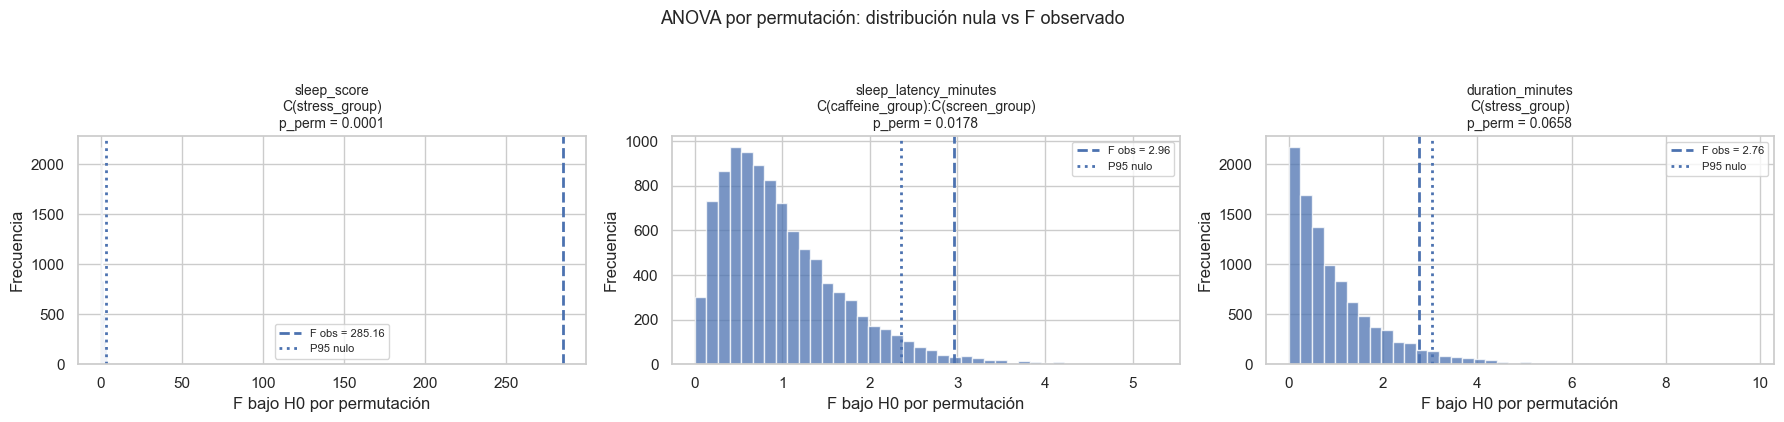

In [75]:
# =========================================================
# 35. PERMUTACIÓN-ANOVA FOCALIZADA (Freedman-Lane)
# =========================================================
# Objetivo:
# Validar con un enfoque no paramétrico los efectos univariados
# más relevantes encontrados en los ANOVAs clásicos.
#
# Esta prueba es útil porque no depende estrictamente de normalidad
# de residuos y permite evaluar si los estadísticos F observados son
# extremos frente a una distribución nula generada por permutaciones.
# =========================================================

from patsy import dmatrices
from scipy.stats import f as f_dist
import time

# ---------------------------------------------------------
# Funciones auxiliares
# ---------------------------------------------------------

def _cols_of_term_anova(term, col_names):
    """
    Identifica las columnas de la matriz de diseño que pertenecen
    exactamente al término evaluado.
    """
    n_colons = term.count(":")
    parts = term.split(":")
    
    cols = []
    for i, c in enumerate(col_names):
        if c == "Intercept":
            continue
        if c.count(":") != n_colons:
            continue
        if all(p in c for p in parts):
            cols.append(i)
    
    return cols


def _rss_from_q(y, Q):
    """
    Calcula RSS usando la proyección QR:
    RSS = ||y||² - ||Q'y||²
    """
    return float(np.sum(y * y) - np.sum((Q.T @ y) ** 2))


def permutation_anova_freedman_lane(
    y_var,
    term,
    data,
    n_perm=9999,
    seed=2025
):
    """
    ANOVA por permutación tipo Freedman-Lane para un término específico.
    
    y_var: variable dependiente
    term: término del modelo que se quiere evaluar
    data: dataframe
    n_perm: número de permutaciones
    seed: semilla para reproducibilidad
    """
    
    formula = f"{y_var} ~ C(caffeine_group) * C(stress_group) * C(screen_group)"
    
    y_df, X_df = dmatrices(formula, data=data, return_type="dataframe")
    y_obs = np.asarray(y_df).ravel()
    X_full = np.asarray(X_df)
    col_names = list(X_df.columns)
    
    n = len(y_obs)
    rng = np.random.default_rng(seed)
    
    # Modelo completo
    Q_full, _ = np.linalg.qr(X_full)
    rank_full = np.linalg.matrix_rank(X_full)
    df_resid_full = n - rank_full
    
    rss_full_obs = _rss_from_q(y_obs, Q_full)
    
    # Modelo reducido: se elimina el término evaluado
    cols_T = _cols_of_term_anova(term, col_names)
    keep_cols = [i for i in range(X_full.shape[1]) if i not in cols_T]
    
    X_red = X_full[:, keep_cols]
    Q_red, _ = np.linalg.qr(X_red)
    rank_red = np.linalg.matrix_rank(X_red)
    
    df_term = rank_full - rank_red
    
    fitted_red_obs = Q_red @ (Q_red.T @ y_obs)
    resid_red_obs = y_obs - fitted_red_obs
    
    rss_red_obs = _rss_from_q(y_obs, Q_red)
    
    # Estadístico F observado
    ss_term_obs = max(rss_red_obs - rss_full_obs, 0)
    F_obs = (ss_term_obs / df_term) / (rss_full_obs / df_resid_full)
    
    # p-valor paramétrico asociado al F parcial
    p_param = f_dist.sf(F_obs, df_term, df_resid_full)
    
    # Tamaño del efecto: eta cuadrado parcial
    eta_p2 = ss_term_obs / (ss_term_obs + rss_full_obs)
    
    # Permutaciones Freedman-Lane
    F_perm = np.zeros(n_perm)
    
    for k in range(n_perm):
        perm = rng.permutation(n)
        
        # Respuesta permutada bajo H0, conservando estructura del modelo reducido
        y_star = fitted_red_obs + resid_red_obs[perm]
        
        rss_full_star = _rss_from_q(y_star, Q_full)
        rss_red_star = _rss_from_q(y_star, Q_red)
        
        ss_term_star = max(rss_red_star - rss_full_star, 0)
        F_perm[k] = (ss_term_star / df_term) / (rss_full_star / df_resid_full)
    
    # p-valor empírico con corrección +1/+1
    p_perm = (np.sum(F_perm >= F_obs) + 1) / (n_perm + 1)
    
    results = {
        "variable_dependiente": y_var,
        "termino_evaluado": term,
        "F_observado": F_obs,
        "df_termino": df_term,
        "df_residual": df_resid_full,
        "p_parametrico": p_param,
        "p_permutacion": p_perm,
        "F_perm_media": np.mean(F_perm),
        "F_perm_p95": np.quantile(F_perm, 0.95),
        "eta_p2_parcial": eta_p2
    }
    
    return results, F_perm


# ---------------------------------------------------------
# Efectos clave a validar
# ---------------------------------------------------------

anova_perm_specs = [
    {
        "y_var": "sleep_score",
        "term": "C(stress_group)",
        "interpretacion": "Validación del efecto principal del estrés sobre la calidad del sueño."
    },
    {
        "y_var": "sleep_latency_minutes",
        "term": "C(caffeine_group):C(screen_group)",
        "interpretacion": "Validación de la interacción cafeína-pantalla sobre la latencia del sueño."
    },
    {
        "y_var": "duration_minutes",
        "term": "C(stress_group)",
        "interpretacion": "Control negativo: evaluación del estrés sobre la duración total del sueño."
    }
]


# ---------------------------------------------------------
# Ejecución de permutaciones
# ---------------------------------------------------------

N_PERM_ANOVA = 9999

anova_perm_records = []
anova_perm_distributions = {}

print(f"Corriendo ANOVA por permutación con {N_PERM_ANOVA} permutaciones\n")

t0 = time.time()

for i, spec in enumerate(anova_perm_specs):
    y_var = spec["y_var"]
    term = spec["term"]
    
    print("="*90)
    print(f"Variable dependiente: {y_var}")
    print(f"Término evaluado: {term}")
    print(spec["interpretacion"])
    
    result, F_perm = permutation_anova_freedman_lane(
        y_var=y_var,
        term=term,
        data=df_model,
        n_perm=N_PERM_ANOVA,
        seed=2025 + i
    )
    
    anova_perm_records.append(result)
    anova_perm_distributions[(y_var, term)] = F_perm
    
    print(f"F observado = {result['F_observado']:.4f}")
    print(f"p paramétrico = {result['p_parametrico']:.5f}")
    print(f"p permutación = {result['p_permutacion']:.5f}")
    print(f"eta² parcial = {result['eta_p2_parcial']:.5f}")
    print()

print(f"Tiempo total: {time.time() - t0:.1f} segundos")


# ---------------------------------------------------------
# Tabla resumen
# ---------------------------------------------------------

tabla_perm_anova = pd.DataFrame(anova_perm_records)

tabla_perm_anova["Convergencia_param_perm"] = (
    (tabla_perm_anova["p_parametrico"] < 0.05) ==
    (tabla_perm_anova["p_permutacion"] < 0.05)
).map({True: "Sí", False: "No"})

print("\n--- Tabla 12. ANOVA paramétrico vs ANOVA por permutación ---")
display(tabla_perm_anova.round(5))


# ---------------------------------------------------------
# Visualización de distribuciones nulas
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1,
    len(anova_perm_specs),
    figsize=(6 * len(anova_perm_specs), 4)
)

if len(anova_perm_specs) == 1:
    axes = [axes]

for ax, spec in zip(axes, anova_perm_specs):
    y_var = spec["y_var"]
    term = spec["term"]
    
    F_perm = anova_perm_distributions[(y_var, term)]
    
    row = tabla_perm_anova[
        (tabla_perm_anova["variable_dependiente"] == y_var) &
        (tabla_perm_anova["termino_evaluado"] == term)
    ].iloc[0]
    
    F_obs = row["F_observado"]
    p_perm = row["p_permutacion"]
    
    ax.hist(F_perm, bins=40, alpha=0.75, edgecolor="white")
    ax.axvline(F_obs, linestyle="--", linewidth=2, label=f"F obs = {F_obs:.2f}")
    ax.axvline(np.quantile(F_perm, 0.95), linestyle=":", linewidth=2, label="P95 nulo")
    
    ax.set_title(f"{y_var}\n{term}\np_perm = {p_perm:.4f}", fontsize=10)
    ax.set_xlabel("F bajo H0 por permutación")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)

plt.suptitle(
    "ANOVA por permutación: distribución nula vs F observado",
    fontsize=13,
    y=1.05
)

plt.tight_layout()
plt.show()

REGRESIÓN LINEAL MÚLTIPLE PARA: sleep_score

Resumen con errores estándar robustos HC3:
                            OLS Regression Results                            
Dep. Variable:            sleep_score   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.239
Method:                 Least Squares   F-statistic:                     1584.
Date:                Tue, 26 May 2026   Prob (F-statistic):               0.00
Time:                        13:46:38   Log-Likelihood:                -59260.
No. Observations:               20000   AIC:                         1.185e+05
Df Residuals:                   19995   BIC:                         1.186e+05
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------

,Predictor,Beta_estandarizado,p_robusto_HC3
0,Intercept,57.86197,0.00000
1,stress_score_z,-2.62364,0.00000
2,caffeine_mg_z,0.02699,0.41370
3,screen_time_before_bed_min_z,0.01379,0.67705
4,caffeine_screen_z,-0.03103,0.34942



Diagnóstico de multicolinealidad:


,Variable,VIF
0,const,1.0
1,stress_c,1.0
2,caffeine_c,1.0
3,screen_c,1.0
4,caffeine_screen_int,1.0



Diagnóstico de supuestos:
Shapiro-Wilk residuos: W = 0.9863, p = 1.2586e-21
Breusch-Pagan homocedasticidad: estadístico = 2.7936, p = 5.9294e-01
Durbin-Watson independencia aproximada: DW = 1.9823
R² = 0.23889
R² ajustado = 0.23874


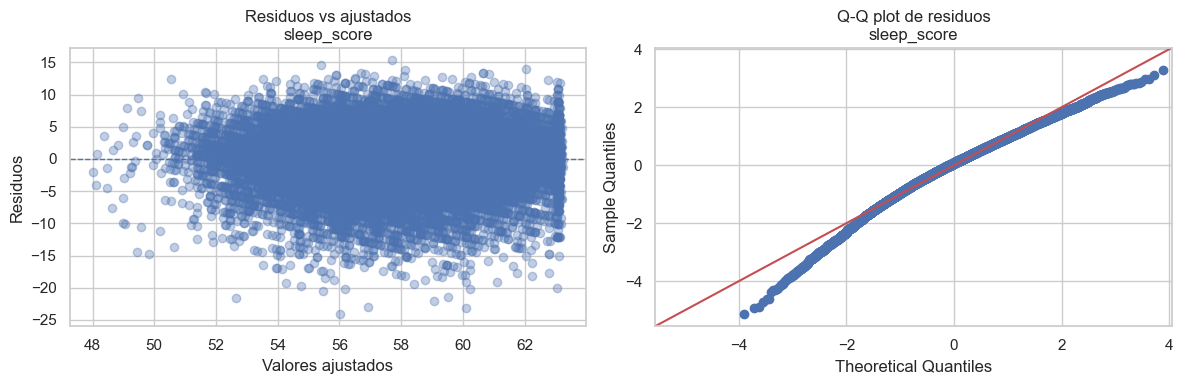

REGRESIÓN LINEAL MÚLTIPLE PARA: sleep_latency_minutes

Resumen con errores estándar robustos HC3:
                              OLS Regression Results                             
Dep. Variable:     sleep_latency_minutes   R-squared:                       0.000
Model:                               OLS   Adj. R-squared:                 -0.000
Method:                    Least Squares   F-statistic:                    0.3821
Date:                   Tue, 26 May 2026   Prob (F-statistic):              0.822
Time:                           13:46:39   Log-Likelihood:                -74769.
No. Observations:                  20000   AIC:                         1.495e+05
Df Residuals:                      19995   BIC:                         1.496e+05
Df Model:                              4                                         
Covariance Type:                     HC3                                         
                          coef    std err          t      P>|t|      [0.025      0

,Predictor,Beta_estandarizado,p_robusto_HC3
0,Intercept,9.66029,0.00000
1,stress_score_z,-0.00401,0.95487
2,caffeine_mg_z,-0.05393,0.43880
3,screen_time_before_bed_min_z,0.06313,0.37420
4,caffeine_screen_z,0.02099,0.76034



Diagnóstico de multicolinealidad:


,Variable,VIF
0,const,1.0
1,stress_c,1.0
2,caffeine_c,1.0
3,screen_c,1.0
4,caffeine_screen_int,1.0



Diagnóstico de supuestos:
Shapiro-Wilk residuos: W = 0.8059, p = 5.0247e-61
Breusch-Pagan homocedasticidad: estadístico = 3.9808, p = 4.0861e-01
Durbin-Watson independencia aproximada: DW = 2.0005
R² = 0.00007
R² ajustado = -0.00013


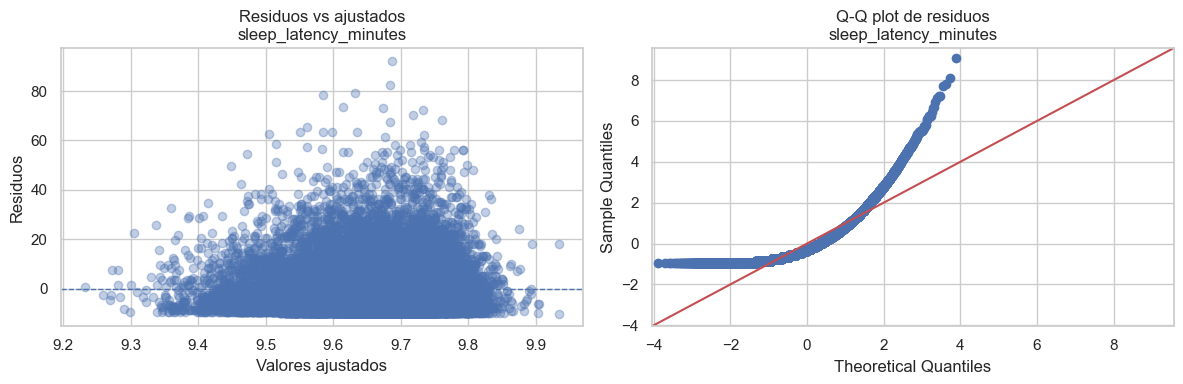

REGRESIÓN LINEAL MÚLTIPLE PARA: duration_minutes

Resumen con errores estándar robustos HC3:
                            OLS Regression Results                            
Dep. Variable:       duration_minutes   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.639
Date:                Tue, 26 May 2026   Prob (F-statistic):              0.161
Time:                        13:46:39   Log-Likelihood:            -1.1388e+05
No. Observations:               20000   AIC:                         2.278e+05
Df Residuals:                   19995   BIC:                         2.278e+05
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

,Predictor,Beta_estandarizado,p_robusto_HC3
0,Intercept,449.18914,0.00000
1,stress_score_z,-0.38285,0.45272
2,caffeine_mg_z,-0.63712,0.21479
3,screen_time_before_bed_min_z,0.98243,0.05522
4,caffeine_screen_z,-0.41737,0.41988



Diagnóstico de multicolinealidad:


,Variable,VIF
0,const,1.0
1,stress_c,1.0
2,caffeine_c,1.0
3,screen_c,1.0
4,caffeine_screen_int,1.0



Diagnóstico de supuestos:
Shapiro-Wilk residuos: W = 0.9998, p = 9.4325e-01
Breusch-Pagan homocedasticidad: estadístico = 4.0374, p = 4.0097e-01
Durbin-Watson independencia aproximada: DW = 2.0074
R² = 0.00033
R² ajustado = 0.00013


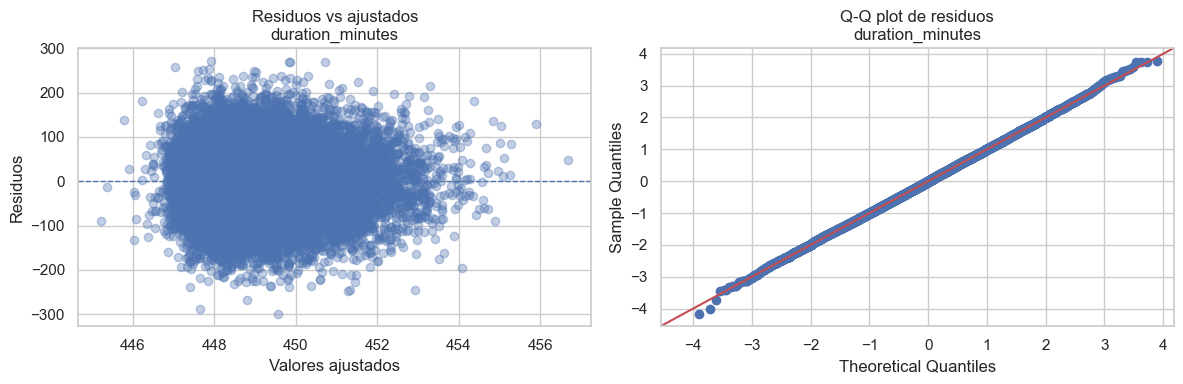


--- Tabla 13. Resumen de regresiones lineales múltiples con errores robustos HC3 ---


,variable_dependiente,predictor,coeficiente,error_std_HC3,t_HC3,p_HC3,IC95_inf_HC3,IC95_sup_HC3,R2,R2_ajustado,p_Breusch_Pagan,p_Shapiro_residuos,Durbin_Watson
0,sleep_score,Intercept,57.86197,0.03313,1746.74128,0.00000,57.79704,57.92690,0.23889,0.23874,0.59294,0.00000,1.98235
1,sleep_score,stress_c,-0.15000,0.00189,-79.54873,0.00000,-0.15370,-0.14631,0.23889,0.23874,0.59294,0.00000,1.98235
2,sleep_score,caffeine_c,0.00052,0.00063,0.81742,0.41370,-0.00072,0.00176,0.23889,0.23874,0.59294,0.00000,1.98235
3,sleep_score,screen_c,0.00037,0.00090,0.41649,0.67705,-0.00138,0.00213,0.23889,0.23874,0.59294,0.00000,1.98235
4,sleep_score,caffeine_screen_int,-0.00002,0.00002,-0.93574,0.34942,-0.00005,0.00002,0.23889,0.23874,0.59294,0.00000,1.98235
5,sleep_latency_minutes,Intercept,9.66029,0.07194,134.29009,0.00000,9.51929,9.80129,0.00007,-0.00013,0.40861,0.00000,2.00054
6,sleep_latency_minutes,stress_c,-0.00023,0.00405,-0.05659,0.95487,-0.00817,0.00771,0.00007,-0.00013,0.40861,0.00000,2.00054
7,sleep_latency_minutes,caffeine_c,-0.00104,0.00134,-0.77424,0.43880,-0.00366,0.00159,0.00007,-0.00013,0.40861,0.00000,2.00054
8,sleep_latency_minutes,screen_c,0.00171,0.00192,0.88866,0.37420,-0.00206,0.00548,0.00007,-0.00013,0.40861,0.00000,2.00054
9,sleep_latency_minutes,caffeine_screen_int,0.00001,0.00004,0.30504,0.76034,-0.00006,0.00008,0.00007,-0.00013,0.40861,0.00000,2.00054



--- Tabla 14. Diagnóstico global de los modelos de regresión ---


,variable_dependiente,R2,R2_ajustado,p_Shapiro_residuos,p_Breusch_Pagan,Durbin_Watson,VIF_max
0,sleep_score,0.23889,0.23874,0.00000,0.59294,1.98235,1.00024
1,sleep_latency_minutes,0.00007,-0.00013,0.00000,0.40861,2.00054,1.00024
2,duration_minutes,0.00033,0.00013,0.94325,0.40097,2.00737,1.00024


In [76]:
# =========================================================
# 36. REGRESIONES LINEALES MÚLTIPLES
# =========================================================
# Objetivo:
# Complementar los análisis factoriales con modelos continuos.
#
# A diferencia de ANOVA/MANOVA, la regresión permite evaluar
# cuánto cambia cada métrica del sueño por cambios continuos
# en estrés, cafeína y tiempo en pantalla.
#
# Se ajustan tres modelos:
#   1. sleep_score
#   2. sleep_latency_minutes
#   3. duration_minutes
#
# Predictores:
#   - stress_score
#   - caffeine_mg
#   - screen_time_before_bed_min
#   - interacción caffeine_mg × screen_time_before_bed_min
#
# Se usan errores estándar robustos HC3 para proteger la inferencia
# ante posibles desviaciones de homocedasticidad.
# =========================================================

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Variables para regresión
# ---------------------------------------------------------

y_vars_reg = [
    "sleep_score",
    "sleep_latency_minutes",
    "duration_minutes"
]

x_vars_reg = [
    "stress_score",
    "caffeine_mg",
    "screen_time_before_bed_min"
]

# Base de trabajo
df_reg = df_model[y_vars_reg + x_vars_reg].dropna().copy()

# Centrado de predictores para mejorar interpretación y reducir
# colinealidad en el término de interacción
df_reg["stress_c"] = df_reg["stress_score"] - df_reg["stress_score"].mean()
df_reg["caffeine_c"] = df_reg["caffeine_mg"] - df_reg["caffeine_mg"].mean()
df_reg["screen_c"] = df_reg["screen_time_before_bed_min"] - df_reg["screen_time_before_bed_min"].mean()

# Interacción continua cafeína × pantalla
df_reg["caffeine_screen_int"] = df_reg["caffeine_c"] * df_reg["screen_c"]

# Variables estandarizadas para comparar magnitud de efectos
for col in ["stress_score", "caffeine_mg", "screen_time_before_bed_min"]:
    df_reg[col + "_z"] = (df_reg[col] - df_reg[col].mean()) / df_reg[col].std()

df_reg["caffeine_screen_z"] = df_reg["caffeine_mg_z"] * df_reg["screen_time_before_bed_min_z"]


# ---------------------------------------------------------
# Función para VIF
# ---------------------------------------------------------

def calcular_vif(data, predictores):
    X = sm.add_constant(data[predictores])
    
    vif = pd.DataFrame({
        "Variable": X.columns,
        "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    })
    
    return vif


# ---------------------------------------------------------
# Función para ajustar e interpretar modelos
# ---------------------------------------------------------

def ajustar_regresion(y_var, data):
    
    print("="*100)
    print(f"REGRESIÓN LINEAL MÚLTIPLE PARA: {y_var}")
    print("="*100)
    
    # Modelo en variables centradas
    formula = f"{y_var} ~ stress_c + caffeine_c + screen_c + caffeine_screen_int"
    modelo = smf.ols(formula, data=data).fit()
    
    # Modelo con errores robustos HC3
    modelo_robusto = modelo.get_robustcov_results(cov_type="HC3")
    
    print("\nResumen con errores estándar robustos HC3:")
    print(modelo_robusto.summary())
    
    # Modelo estandarizado para comparar importancia relativa
    formula_z = f"{y_var} ~ stress_score_z + caffeine_mg_z + screen_time_before_bed_min_z + caffeine_screen_z"
    modelo_z = smf.ols(formula_z, data=data).fit()
    modelo_z_robusto = modelo_z.get_robustcov_results(cov_type="HC3")
    
    print("\nCoeficientes estandarizados:")
    coef_z = pd.DataFrame({
        "Predictor": modelo_z.params.index,
        "Beta_estandarizado": modelo_z.params.values,
        "p_robusto_HC3": modelo_z_robusto.pvalues
    })
    display(coef_z.round(5))
    
    # Diagnóstico de multicolinealidad
    predictores_vif = ["stress_c", "caffeine_c", "screen_c", "caffeine_screen_int"]
    vif = calcular_vif(data, predictores_vif)
    
    print("\nDiagnóstico de multicolinealidad:")
    display(vif.round(3))
    
    # Residuos
    residuos = modelo.resid
    ajustados = modelo.fittedvalues
    
    # Shapiro-Wilk sobre muestra si n es muy grande
    if len(residuos) > 5000:
        residuos_shapiro = residuos.sample(5000, random_state=42)
    else:
        residuos_shapiro = residuos
    
    shapiro_stat, shapiro_p = shapiro(residuos_shapiro)
    
    # Breusch-Pagan
    bp_stat, bp_p, _, _ = het_breuschpagan(residuos, modelo.model.exog)
    
    # Durbin-Watson
    dw = durbin_watson(residuos)
    
    print("\nDiagnóstico de supuestos:")
    print(f"Shapiro-Wilk residuos: W = {shapiro_stat:.4f}, p = {shapiro_p:.4e}")
    print(f"Breusch-Pagan homocedasticidad: estadístico = {bp_stat:.4f}, p = {bp_p:.4e}")
    print(f"Durbin-Watson independencia aproximada: DW = {dw:.4f}")
    print(f"R² = {modelo.rsquared:.5f}")
    print(f"R² ajustado = {modelo.rsquared_adj:.5f}")
    
    # Gráficos diagnósticos
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    axes[0].scatter(ajustados, residuos, alpha=0.35)
    axes[0].axhline(0, linestyle="--", linewidth=1)
    axes[0].set_xlabel("Valores ajustados")
    axes[0].set_ylabel("Residuos")
    axes[0].set_title(f"Residuos vs ajustados\n{y_var}")
    
    sm.qqplot(residuos, line="45", fit=True, ax=axes[1])
    axes[1].set_title(f"Q-Q plot de residuos\n{y_var}")
    
    plt.tight_layout()
    plt.show()
    
    return {
        "modelo": modelo,
        "modelo_robusto": modelo_robusto,
        "modelo_z": modelo_z,
        "modelo_z_robusto": modelo_z_robusto,
        "vif": vif,
        "shapiro_p": shapiro_p,
        "breusch_pagan_p": bp_p,
        "durbin_watson": dw,
        "r2": modelo.rsquared,
        "r2_ajustado": modelo.rsquared_adj
    }


# ---------------------------------------------------------
# Ejecutar las tres regresiones
# ---------------------------------------------------------

resultados_regresiones = {}

for y in y_vars_reg:
    resultados_regresiones[y] = ajustar_regresion(y, df_reg)


# ---------------------------------------------------------
# Tabla resumen de coeficientes robustos
# ---------------------------------------------------------

resumen_coeficientes = []

for y, res in resultados_regresiones.items():
    
    modelo = res["modelo"]
    modelo_robusto = res["modelo_robusto"]
    
    conf_int = modelo_robusto.conf_int()
    
    tabla = pd.DataFrame({
        "variable_dependiente": y,
        "predictor": modelo.params.index,
        "coeficiente": modelo.params.values,
        "error_std_HC3": modelo_robusto.bse,
        "t_HC3": modelo_robusto.tvalues,
        "p_HC3": modelo_robusto.pvalues,
        "IC95_inf_HC3": conf_int[:, 0],
        "IC95_sup_HC3": conf_int[:, 1],
        "R2": res["r2"],
        "R2_ajustado": res["r2_ajustado"],
        "p_Breusch_Pagan": res["breusch_pagan_p"],
        "p_Shapiro_residuos": res["shapiro_p"],
        "Durbin_Watson": res["durbin_watson"]
    })
    
    resumen_coeficientes.append(tabla)

tabla_regresiones = pd.concat(resumen_coeficientes, ignore_index=True)

print("\n--- Tabla 13. Resumen de regresiones lineales múltiples con errores robustos HC3 ---")
display(tabla_regresiones.round(5))


# ---------------------------------------------------------
# Tabla compacta de bondad de ajuste y supuestos
# ---------------------------------------------------------

tabla_diagnostico_regresion = pd.DataFrame([
    {
        "variable_dependiente": y,
        "R2": res["r2"],
        "R2_ajustado": res["r2_ajustado"],
        "p_Shapiro_residuos": res["shapiro_p"],
        "p_Breusch_Pagan": res["breusch_pagan_p"],
        "Durbin_Watson": res["durbin_watson"],
        "VIF_max": res["vif"]["VIF"].dropna().max()
    }
    for y, res in resultados_regresiones.items()
])

print("\n--- Tabla 14. Diagnóstico global de los modelos de regresión ---")
display(tabla_diagnostico_regresion.round(5))

In [77]:
# =========================================================
# 37. COEFICIENTES COMPLETAMENTE ESTANDARIZADOS
# =========================================================
# En esta celda se estandarizan tanto las variables dependientes
# como los predictores. Así los coeficientes pueden interpretarse
# como betas estandarizados clásicos.
# =========================================================

df_reg_std_full = df_reg.copy()

# Estandarizar variables dependientes
for y in y_vars_reg:
    df_reg_std_full[y + "_z"] = (df_reg_std_full[y] - df_reg_std_full[y].mean()) / df_reg_std_full[y].std()

# Los predictores ya estaban estandarizados:
# stress_score_z, caffeine_mg_z, screen_time_before_bed_min_z, caffeine_screen_z

betas_estandarizados = []

for y in y_vars_reg:
    
    y_z = y + "_z"
    
    formula_std = (
        f"{y_z} ~ stress_score_z + caffeine_mg_z + "
        f"screen_time_before_bed_min_z + caffeine_screen_z"
    )
    
    modelo_std = smf.ols(formula_std, data=df_reg_std_full).fit()
    modelo_std_hc3 = modelo_std.get_robustcov_results(cov_type="HC3")
    
    tabla_beta = pd.DataFrame({
        "variable_dependiente": y,
        "predictor": modelo_std.params.index,
        "beta_estandarizado": modelo_std.params.values,
        "p_HC3": modelo_std_hc3.pvalues,
        "IC95_inf": modelo_std_hc3.conf_int()[:, 0],
        "IC95_sup": modelo_std_hc3.conf_int()[:, 1],
        "R2": modelo_std.rsquared,
        "R2_ajustado": modelo_std.rsquared_adj
    })
    
    betas_estandarizados.append(tabla_beta)

tabla_betas_estandarizados = pd.concat(betas_estandarizados, ignore_index=True)

print("--- Tabla 15. Coeficientes completamente estandarizados de las regresiones ---")
display(tabla_betas_estandarizados.round(5))

--- Tabla 15. Coeficientes completamente estandarizados de las regresiones ---


,variable_dependiente,predictor,beta_estandarizado,p_HC3,IC95_inf,IC95_sup,R2,R2_ajustado
0,sleep_score,Intercept,0.00000,0.99948,-0.01209,0.01210,0.23889,0.23874
1,sleep_score,stress_score_z,-0.48870,0.00000,-0.50074,-0.47666,0.23889,0.23874
2,sleep_score,caffeine_mg_z,0.00503,0.41370,-0.00703,0.01708,0.23889,0.23874
3,sleep_score,screen_time_before_bed_min_z,0.00257,0.67705,-0.00952,0.01466,0.23889,0.23874
4,sleep_score,caffeine_screen_z,-0.00578,0.34942,-0.01789,0.00633,0.23889,0.23874
5,sleep_latency_minutes,Intercept,-0.00000,0.99984,-0.01386,0.01386,0.00007,-0.00013
6,sleep_latency_minutes,stress_score_z,-0.00039,0.95487,-0.01405,0.01326,0.00007,-0.00013
7,sleep_latency_minutes,caffeine_mg_z,-0.00530,0.43880,-0.01872,0.00812,0.00007,-0.00013
8,sleep_latency_minutes,screen_time_before_bed_min_z,0.00621,0.37420,-0.00748,0.01990,0.00007,-0.00013
9,sleep_latency_minutes,caffeine_screen_z,0.00206,0.76034,-0.01120,0.01532,0.00007,-0.00013


In [78]:
# =========================================================
# 38. INTEGRACIÓN DE RESULTADOS: CONVERGENCIA ENTRE MÉTODOS
# =========================================================
# Objetivo:
# Sintetizar cómo los distintos métodos estadísticos convergen
# o divergen respecto a las hipótesis centrales del estudio.
# =========================================================

tabla_convergencia = pd.DataFrame({
    "Pregunta estadística": [
        "¿El estrés modifica el perfil global del sueño?",
        "¿El estrés afecta la calidad del sueño?",
        "¿El estrés afecta la duración total del sueño?",
        "¿La interacción cafeína × pantalla afecta la latencia?",
        "¿Cafeína y pantalla predicen linealmente la calidad del sueño?",
        "¿Los predictores explican linealmente la latencia?",
        "¿Los predictores explican linealmente la duración?"
    ],
    
    "Métodos que responden": [
        "MANOVA clásico + MANOVA por permutación",
        "ANOVA clásico + Tukey + ANOVA por permutación + regresión",
        "ANOVA clásico + ANOVA por permutación + regresión",
        "ANOVA clásico + ANOVA por permutación + regresión",
        "Regresión lineal múltiple",
        "Regresión lineal múltiple",
        "Regresión lineal múltiple"
    ],
    
    "Resultado principal": [
        "El estrés mostró el efecto multivariado más consistente sobre el conjunto de variables del sueño.",
        "El estrés fue significativo; en regresión, β estandarizado = -0.489 y R² ≈ 0.239.",
        "No se encontró evidencia robusta de efecto del estrés sobre la duración.",
        "La permutación ANOVA confirmó una interacción significativa, pero con tamaño de efecto muy pequeño.",
        "No fueron predictores significativos de sleep_score.",
        "El modelo presentó R² ≈ 0.00007 y ningún predictor significativo.",
        "El modelo presentó R² ≈ 0.00033; ningún predictor fue significativo al nivel 0.05."
    ],
    
    "Interpretación biomédica": [
        "El estrés parece modular el sueño como fenómeno multidimensional, especialmente su calidad global.",
        "A mayor estrés percibido, menor calidad del sueño; este es el hallazgo más sólido del estudio.",
        "El estrés no necesariamente reduce el tiempo total dormido, sino la calidad del descanso.",
        "La combinación cafeína-pantalla podría alterar la conciliación del sueño en ciertos grupos, pero el efecto es pequeño.",
        "Cafeína y pantalla no explican directamente la calidad global del sueño en un modelo lineal.",
        "La latencia podría depender de mecanismos no lineales, hábitos individuales o factores no medidos.",
        "La duración del sueño parece estar determinada por otros factores no incluidos en el modelo."
    ],
    
    "Fuerza de evidencia": [
        "Alta",
        "Muy alta",
        "Baja / no significativa",
        "Moderada estadísticamente, baja en tamaño de efecto",
        "Baja / no significativa",
        "Muy baja",
        "Muy baja"
    ]
})

display(tabla_convergencia)

,Pregunta estadística,Métodos que responden,Resultado principal,Interpretación biomédica,Fuerza de evidencia
0,¿El estrés modifica el perfil global del sueño?,MANOVA clásico + MANOVA por permutación,El estrés mostró el efecto multivariado más co...,El estrés parece modular el sueño como fenómen...,Alta
1,¿El estrés afecta la calidad del sueño?,ANOVA clásico + Tukey + ANOVA por permutación ...,"El estrés fue significativo; en regresión, β e...","A mayor estrés percibido, menor calidad del su...",Muy alta
2,¿El estrés afecta la duración total del sueño?,ANOVA clásico + ANOVA por permutación + regresión,No se encontró evidencia robusta de efecto del...,El estrés no necesariamente reduce el tiempo t...,Baja / no significativa
3,¿La interacción cafeína × pantalla afecta la l...,ANOVA clásico + ANOVA por permutación + regresión,La permutación ANOVA confirmó una interacción ...,La combinación cafeína-pantalla podría alterar...,"Moderada estadísticamente, baja en tamaño de e..."
4,¿Cafeína y pantalla predicen linealmente la ca...,Regresión lineal múltiple,No fueron predictores significativos de sleep_...,Cafeína y pantalla no explican directamente la...,Baja / no significativa
5,¿Los predictores explican linealmente la laten...,Regresión lineal múltiple,El modelo presentó R² ≈ 0.00007 y ningún predi...,La latencia podría depender de mecanismos no l...,Muy baja
6,¿Los predictores explican linealmente la durac...,Regresión lineal múltiple,El modelo presentó R² ≈ 0.00033; ningún predic...,La duración del sueño parece estar determinada...,Muy baja


### Integración general de los resultados

Los resultados obtenidos muestran una convergencia clara entre los métodos estadísticos aplicados. Tanto el MANOVA como los análisis univariados y las pruebas por permutación indican que el estrés percibido es el factor más relevante para explicar cambios en el perfil del sueño. Sin embargo, este efecto no se distribuye de manera uniforme sobre todas las dimensiones evaluadas: la evidencia es fuerte para la calidad global del sueño, pero débil o inexistente para la duración total y la latencia cuando estas se analizan mediante modelos lineales continuos.

La regresión lineal múltiple permitió complementar los análisis factoriales al conservar las variables predictoras en su escala continua. Este análisis confirmó que el estrés es el único predictor significativo de `sleep_score`, con un coeficiente estandarizado negativo de magnitud moderada. En contraste, la cafeína, el tiempo en pantalla y su interacción no predijeron significativamente la calidad del sueño. Además, los modelos para `sleep_latency_minutes` y `duration_minutes` presentaron valores de R² cercanos a cero, lo que sugiere que estas variables no son explicadas adecuadamente por relaciones lineales simples con los predictores considerados.

En conjunto, los resultados sugieren que el estrés percibido deteriora principalmente la calidad del sueño, más que su cantidad total. La interacción entre cafeína y tiempo en pantalla sobre la latencia aparece como un hallazgo estadísticamente detectable, pero con tamaño de efecto muy pequeño, por lo que debe interpretarse con cautela. Desde una perspectiva biomédica, esto indica que las intervenciones orientadas a mejorar el descanso deberían priorizar el manejo del estrés y no limitarse únicamente a modificar hábitos aislados como el consumo de cafeína o el uso de pantallas antes de dormir.
